# 0b. Probability and Score Functions for Diffusion Models

This notebook bridges the math foundations from notebook 0a to the probabilistic concepts at the heart of diffusion models:

- **Gaussian distributions**: 1D, 2D, mixtures; the building blocks of diffusion noise
- **Gaussian algebra**: sums, linear maps and Bayes' rule for Gaussians, the three facts behind every DDPM formula
- **Score functions**: $\nabla_x \log p(x)$, the gradient of log-probability; the key object that diffusion models learn
- **KL divergence, maximum likelihood and the ELBO**: what "training a generative model" optimises
- **Langevin dynamics**: sampling from a distribution using only its score function, and why its noise level is not a free parameter
- **The noising process**: how adding Gaussian noise progressively destroys structure
- **Denoising as score estimation**: why MSE regression learns conditional means, Tweedie's formula, and denoising score matching, the conceptual bridge to DDPM

By the end, you'll see exactly *why* diffusion models work the way they do.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib import cm
from scipy.stats import norm, multivariate_normal

plt.rcParams['figure.figsize'] = (8, 6)
plt.rcParams['font.size'] = 12

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cpu


---
## 1. Gaussian Distributions

The Gaussian (normal) distribution is the foundation of diffusion models. The forward process adds Gaussian noise, and the reverse process removes it.

### 1.1 The 1D Gaussian

$$p(x) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left(-\frac{(x - \mu)^2}{2\sigma^2}\right)$$

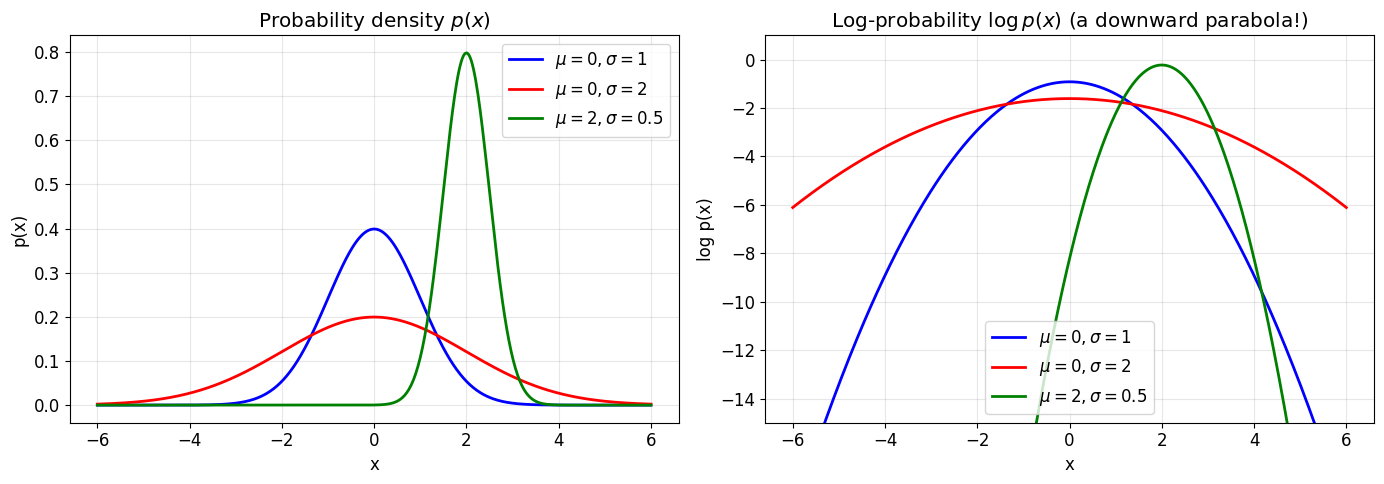

In [2]:
x = np.linspace(-6, 6, 500)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Different means and variances
for mu, sigma, color in [(0, 1, 'blue'), (0, 2, 'red'), (2, 0.5, 'green')]:
    pdf = norm.pdf(x, mu, sigma)
    ax1.plot(x, pdf, color=color, linewidth=2, label=f'$\\mu={mu}, \\sigma={sigma}$')
    # Also show log-probability
    log_pdf = norm.logpdf(x, mu, sigma)
    ax2.plot(x, log_pdf, color=color, linewidth=2, label=f'$\\mu={mu}, \\sigma={sigma}$')

ax1.set_title('Probability density $p(x)$')
ax1.set_xlabel('x'); ax1.set_ylabel('p(x)')
ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.set_title('Log-probability $\\log p(x)$ (a downward parabola!)')
ax2.set_xlabel('x'); ax2.set_ylabel('log p(x)')
ax2.set_ylim(-15, 1)
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Key observation**: The log-probability of a Gaussian is a *downward parabola*. Its gradient (the score function) is therefore *linear* — this makes Gaussians very tractable to work with analytically.

### 1.2 The 2D Gaussian

$$p(\mathbf{x}) = \frac{1}{2\pi|\Sigma|^{1/2}} \exp\left(-\frac{1}{2}(\mathbf{x} - \boldsymbol{\mu})^T \Sigma^{-1} (\mathbf{x} - \boldsymbol{\mu})\right)$$

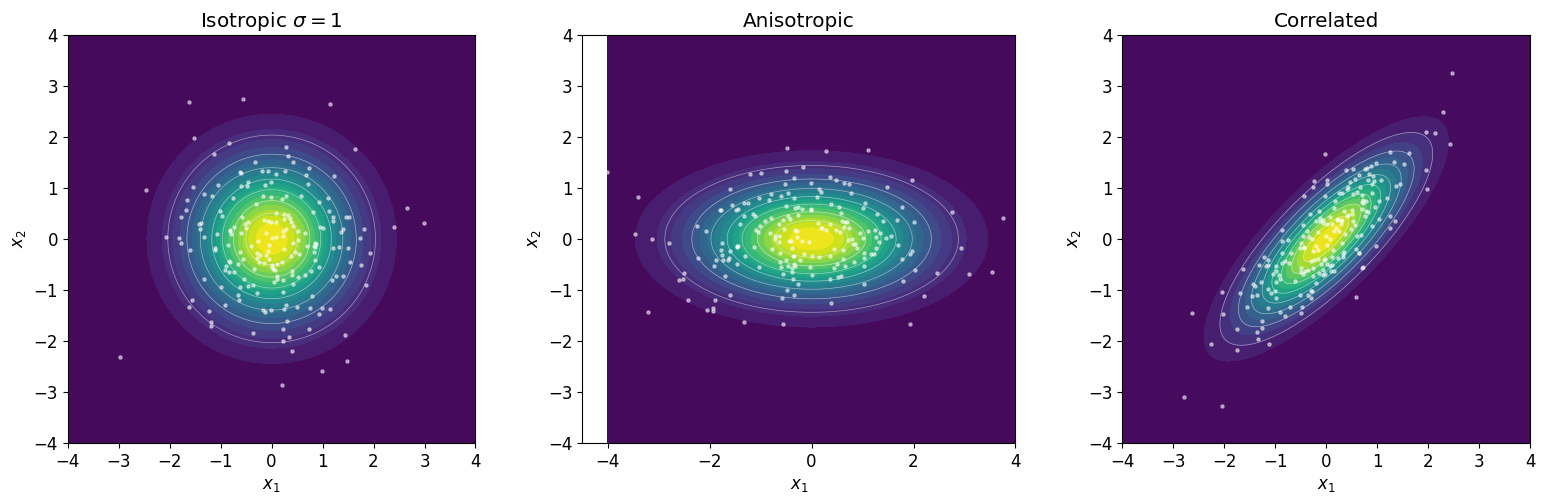

In [3]:
# 2D Gaussians with different covariance structures
x = np.linspace(-4, 4, 200)
y = np.linspace(-4, 4, 200)
X, Y = np.meshgrid(x, y)
pos = np.dstack((X, Y))

gaussians = {
    'Isotropic $\\sigma=1$': {'mean': [0, 0], 'cov': [[1, 0], [0, 1]]},
    'Anisotropic': {'mean': [0, 0], 'cov': [[2, 0], [0, 0.5]]},
    'Correlated': {'mean': [0, 0], 'cov': [[1, 0.8], [0.8, 1]]},
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, params) in zip(axes, gaussians.items()):
    rv = multivariate_normal(params['mean'], params['cov'])
    Z = rv.pdf(pos)
    
    ax.contourf(X, Y, Z, levels=20, cmap='viridis')
    ax.contour(X, Y, Z, levels=8, colors='white', linewidths=0.5, alpha=0.5)
    
    # Draw samples
    samples = rv.rvs(size=200)
    ax.scatter(samples[:, 0], samples[:, 1], s=5, c='white', alpha=0.5)
    
    ax.set_title(name)
    ax.set_aspect('equal')
    ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')

plt.tight_layout()
plt.show()

### 1.3 Mixture of Gaussians

Real data distributions are usually *not* Gaussian. A mixture of Gaussians is a simple but multimodal distribution that's useful for testing:

$$p(x) = \sum_{k=1}^K \pi_k \cdot \mathcal{N}(x; \mu_k, \Sigma_k)$$

Diffusion models can learn to generate from complex multimodal distributions — that's what makes them powerful.

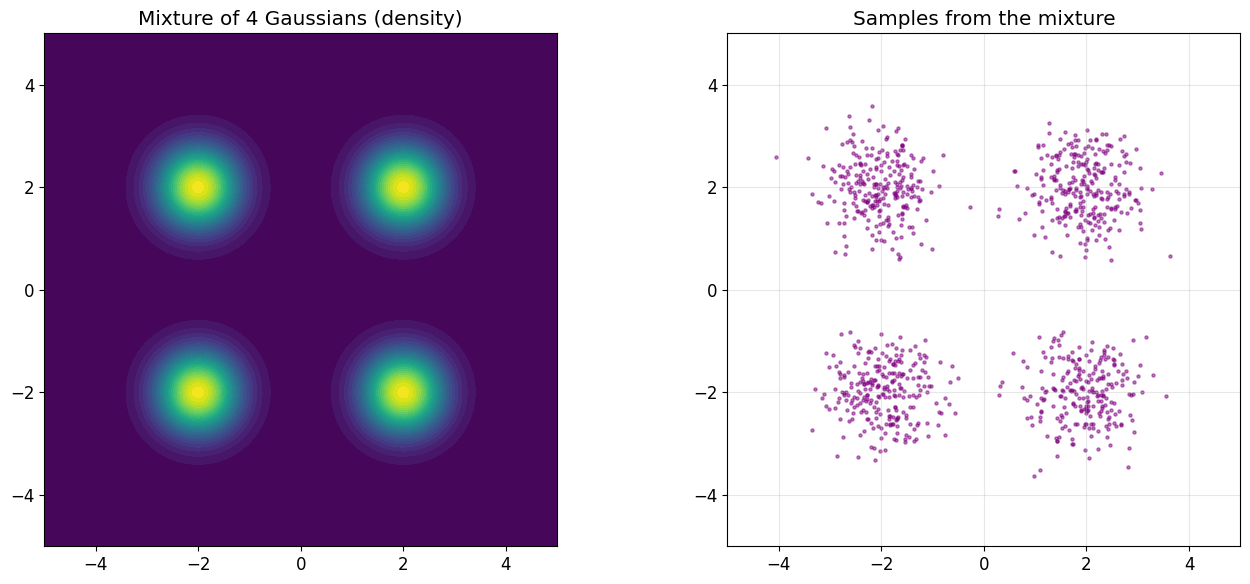

In [4]:
# Define a mixture of 4 Gaussians
mixture_params = [
    {'mean': [2, 2], 'cov': [[0.3, 0], [0, 0.3]], 'weight': 0.25},
    {'mean': [-2, 2], 'cov': [[0.3, 0], [0, 0.3]], 'weight': 0.25},
    {'mean': [2, -2], 'cov': [[0.3, 0], [0, 0.3]], 'weight': 0.25},
    {'mean': [-2, -2], 'cov': [[0.3, 0], [0, 0.3]], 'weight': 0.25},
]

def mixture_pdf(pos, params):
    """Compute mixture density at positions."""
    density = np.zeros(pos.shape[:-1])
    for p in params:
        rv = multivariate_normal(p['mean'], p['cov'])
        density += p['weight'] * rv.pdf(pos)
    return density

def sample_mixture(params, n_samples):
    """Sample from a Gaussian mixture."""
    samples = []
    weights = [p['weight'] for p in params]
    component_indices = np.random.choice(len(params), size=n_samples, p=weights)
    for i in range(n_samples):
        p = params[component_indices[i]]
        sample = np.random.multivariate_normal(p['mean'], p['cov'])
        samples.append(sample)
    return np.array(samples)

x = np.linspace(-5, 5, 200)
y = np.linspace(-5, 5, 200)
X, Y = np.meshgrid(x, y)
pos = np.dstack((X, Y))

Z = mixture_pdf(pos, mixture_params)
samples = sample_mixture(mixture_params, 1000)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.contourf(X, Y, Z, levels=30, cmap='viridis')
ax1.set_title('Mixture of 4 Gaussians (density)')
ax1.set_aspect('equal')

ax2.scatter(samples[:, 0], samples[:, 1], s=5, alpha=0.5, c='purple')
ax2.set_title('Samples from the mixture')
ax2.set_xlim(-5, 5); ax2.set_ylim(-5, 5)
ax2.set_aspect('equal')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 1.4 Gaussian algebra: the three facts behind every DDPM formula

Almost every equation in notebooks 1–3 follows from three properties of Gaussians.

**(a) Linear maps and independent sums stay Gaussian.** If $x \sim \mathcal{N}(\mu, \sigma^2)$ and $\epsilon \sim \mathcal{N}(0,1)$ are independent, then $a x + b\epsilon \sim \mathcal{N}(a\mu,\ a^2\sigma^2 + b^2)$. **Variances add; standard deviations don't.** That is why two noising steps collapse into one:

$$x_2 = \sqrt{\alpha_2}\big(\sqrt{\alpha_1}x_0 + \sqrt{1-\alpha_1}\epsilon_1\big) + \sqrt{1-\alpha_2}\,\epsilon_2 \;\sim\; \mathcal{N}\big(\sqrt{\alpha_1\alpha_2}\,x_0,\ 1 - \alpha_1\alpha_2\big)$$

**(b) Reparameterization.** Sampling $z \sim \mathcal{N}(\mu, \sigma^2)$ is the same as computing $z = \mu + \sigma\epsilon$ with $\epsilon \sim \mathcal{N}(0,1)$. This is how $x_t$ is drawn in one line, and how VAEs backpropagate through sampling (0c).

**(c) Bayes' rule for Gaussians.** If $(u, w)$ are jointly Gaussian, then $u \mid w$ is Gaussian with

$$\mathbb{E}[u \mid w] = \mathbb{E}[u] + \frac{\text{Cov}(u,w)}{\text{Var}(w)}\big(w - \mathbb{E}[w]\big), \qquad \text{Var}(u \mid w) = \text{Var}(u) - \frac{\text{Cov}(u,w)^2}{\text{Var}(w)}$$

Applied to the DDPM chain with $x_0$ held fixed, this gives the **reverse posterior** $q(x_{t-1} \mid x_t, x_0)$, the target that DDPM's reverse step imitates:

$$\tilde\mu_t = \frac{\sqrt{\bar\alpha_{t-1}}\,\beta_t}{1-\bar\alpha_t}\,x_0 + \frac{\sqrt{\alpha_t}\,(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}\,x_t, \qquad \tilde\beta_t = \frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\,\beta_t$$

Let's check (a) and (c) by simulation.

In [5]:
torch.manual_seed(0)
N = 2_000_000
x0_fixed = 1.5                                        # condition on one data point
a1, a2 = 1 - 0.1, 1 - 0.3                             # alpha_1, alpha_2  (beta = 0.1, 0.3)
x1 = np.sqrt(a1) * x0_fixed + np.sqrt(1 - a1) * torch.randn(N)
x2 = np.sqrt(a2) * x1 + np.sqrt(1 - a2) * torch.randn(N)

ab1, ab2 = a1, a1 * a2                                # alpha_bar_1, alpha_bar_2
print("(a) two steps vs. closed form")
print(f"    mean of x2: simulated {x2.mean():.4f}   closed form sqrt(ab2)*x0 = {np.sqrt(ab2) * x0_fixed:.4f}")
print(f"    var  of x2: simulated {x2.var():.4f}   closed form 1 - ab2      = {1 - ab2:.4f}")

# (c) posterior q(x1 | x2, x0): look at x1 among samples whose x2 landed near a chosen value
x2_obs = 0.3
sel = (x2 - x2_obs).abs() < 0.01
beta2 = 1 - a2
mu_tilde = np.sqrt(ab1) * beta2 / (1 - ab2) * x0_fixed + np.sqrt(a2) * (1 - ab1) / (1 - ab2) * x2_obs
var_tilde = (1 - ab1) / (1 - ab2) * beta2
print(f"\n(c) posterior of x1 given x2 = {x2_obs} (and x0 = {x0_fixed}), from {sel.sum().item()} samples")
print(f"    mean: simulated {x1[sel].mean():.4f}   formula mu_tilde   = {mu_tilde:.4f}")
print(f"    var:  simulated {x1[sel].var():.4f}   formula beta_tilde = {var_tilde:.4f}")

(a) two steps vs. closed form
    mean of x2: simulated 1.1905   closed form sqrt(ab2)*x0 = 1.1906
    var  of x2: simulated 0.3701   closed form 1 - ab2      = 0.3700

(c) posterior of x1 given x2 = 0.3 (and x0 = 1.5), from 8987 samples
    mean: simulated 1.2168   formula mu_tilde   = 1.2216
    var:  simulated 0.0816   formula beta_tilde = 0.0811


---
## 2. The Score Function

The **score function** is the gradient of the log-probability density:

$$\mathbf{s}(\mathbf{x}) = \nabla_\mathbf{x} \log p(\mathbf{x})$$

This is a *vector field* that points toward regions of higher probability. It tells you: "from this point, which direction increases the probability density the fastest?"

**Why this matters for diffusion models**: Instead of learning $p(x)$ directly (which requires knowing the normalizing constant), diffusion models learn the *score function*, which doesn't require normalization.

### 2.1 Score of a Gaussian

For $p(x) = \mathcal{N}(x; \mu, \sigma^2)$:

$$\log p(x) = -\frac{(x - \mu)^2}{2\sigma^2} + \text{const}$$

$$s(x) = \nabla_x \log p(x) = -\frac{x - \mu}{\sigma^2}$$

The score is simply a linear function pointing toward the mean!

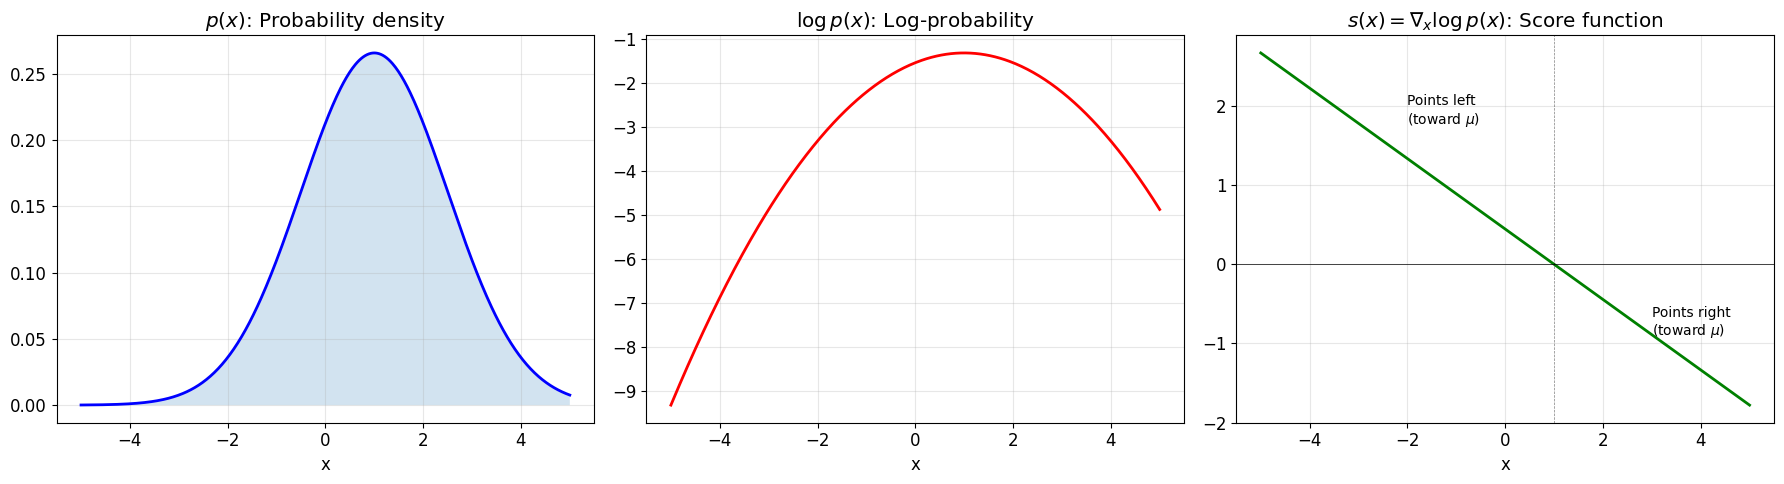

In [6]:
# 1D Score function of a Gaussian
x = np.linspace(-5, 5, 500)
mu, sigma = 1.0, 1.5

pdf = norm.pdf(x, mu, sigma)
log_pdf = norm.logpdf(x, mu, sigma)
score = -(x - mu) / sigma**2  # analytical score

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(x, pdf, 'b-', linewidth=2)
axes[0].fill_between(x, pdf, alpha=0.2)
axes[0].set_title('$p(x)$: Probability density')
axes[0].set_xlabel('x'); axes[0].grid(True, alpha=0.3)

axes[1].plot(x, log_pdf, 'r-', linewidth=2)
axes[1].set_title('$\\log p(x)$: Log-probability')
axes[1].set_xlabel('x'); axes[1].grid(True, alpha=0.3)

axes[2].plot(x, score, 'g-', linewidth=2)
axes[2].axhline(y=0, color='k', linewidth=0.5)
axes[2].axvline(x=mu, color='k', linewidth=0.5, linestyle='--', alpha=0.5)
axes[2].set_title('$s(x) = \\nabla_x \\log p(x)$: Score function')
axes[2].set_xlabel('x'); axes[2].grid(True, alpha=0.3)
axes[2].annotate('Points left\n(toward $\\mu$)', xy=(-2, score[100]), fontsize=10)
axes[2].annotate('Points right\n(toward $\\mu$)', xy=(3, score[400]), fontsize=10)

plt.tight_layout()
plt.show()

**Intuition**: The score function is zero at the mean (you're already at the peak), positive for $x < \mu$ (move right toward the peak), and negative for $x > \mu$ (move left toward the peak). Its magnitude is larger when you're farther from the mean.

### 2.2 Score of a 2D Gaussian — visualized as a vector field

For a 2D Gaussian $\mathcal{N}(\boldsymbol{\mu}, \Sigma)$:

$$\nabla_\mathbf{x} \log p(\mathbf{x}) = -\Sigma^{-1}(\mathbf{x} - \boldsymbol{\mu})$$

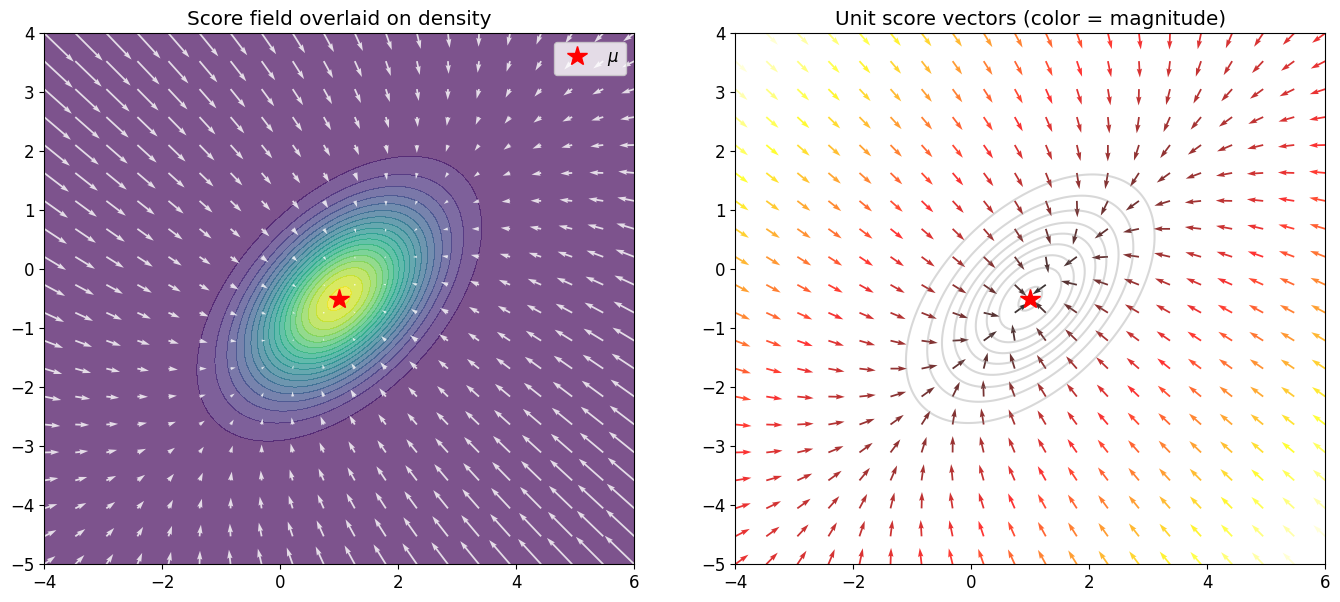

In [7]:
# Score field of a 2D Gaussian
mu = np.array([1.0, -0.5])
cov = np.array([[1.0, 0.5], [0.5, 1.0]])
cov_inv = np.linalg.inv(cov)

x = np.linspace(-4, 6, 200)
y = np.linspace(-5, 4, 200)
X, Y = np.meshgrid(x, y)
pos = np.dstack((X, Y))

# Density
rv = multivariate_normal(mu, cov)
Z = rv.pdf(pos)

# Score field on a coarser grid
x_q = np.linspace(-4, 6, 20)
y_q = np.linspace(-5, 4, 20)
Xq, Yq = np.meshgrid(x_q, y_q)

# s(x) = -Sigma^{-1} (x - mu)
# For each grid point
Sq_x = np.zeros_like(Xq)
Sq_y = np.zeros_like(Yq)
for i in range(Xq.shape[0]):
    for j in range(Xq.shape[1]):
        diff = np.array([Xq[i,j] - mu[0], Yq[i,j] - mu[1]])
        score = -cov_inv @ diff
        Sq_x[i,j] = score[0]
        Sq_y[i,j] = score[1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Density contours + score arrows
ax1.contourf(X, Y, Z, levels=20, cmap='viridis', alpha=0.7)
ax1.quiver(Xq, Yq, Sq_x, Sq_y, color='white', alpha=0.8)
ax1.plot(mu[0], mu[1], 'r*', markersize=15, label='$\\mu$')
ax1.set_title('Score field overlaid on density')
ax1.legend(); ax1.set_aspect('equal')

# Score magnitude
score_mag = np.sqrt(Sq_x**2 + Sq_y**2)
norm_Sq_x = Sq_x / (score_mag + 1e-8)
norm_Sq_y = Sq_y / (score_mag + 1e-8)
ax2.quiver(Xq, Yq, norm_Sq_x, norm_Sq_y, score_mag, cmap='hot', alpha=0.8)
ax2.contour(X, Y, Z, levels=10, colors='gray', alpha=0.3)
ax2.plot(mu[0], mu[1], 'r*', markersize=15)
ax2.set_title('Unit score vectors (color = magnitude)')
ax2.set_aspect('equal')

plt.tight_layout()
plt.show()

**Every arrow points toward the mean** — the score function always points toward higher probability. Near the mean, arrows are small (you're already at high probability). Far away, arrows are large (strong pull back toward the center).

### 2.3 Score of a Gaussian mixture

For a mixture $p(x) = \sum_k \pi_k\,\mathcal{N}(x; \mu_k, \Sigma_k)$, differentiating $\log p$ gives a weighted average of the component scores:

$$\nabla_x \log p(x) = \sum_k w_k(x)\,\big(-\Sigma_k^{-1}(x - \mu_k)\big), \qquad w_k(x) = \frac{\pi_k\,\mathcal{N}(x;\mu_k,\Sigma_k)}{p(x)} = P(\text{component } k \mid x)$$

The weights $w_k(x)$ are the **responsibilities**: the posterior probability that $x$ came from component $k$. Near a mode one responsibility is $\approx 1$ and the score points at that mode; in between, the score is a blend. This "posterior-weighted average" structure reappears in the optimal denoiser (section 6) and in the marginal flow-matching velocity (3b).

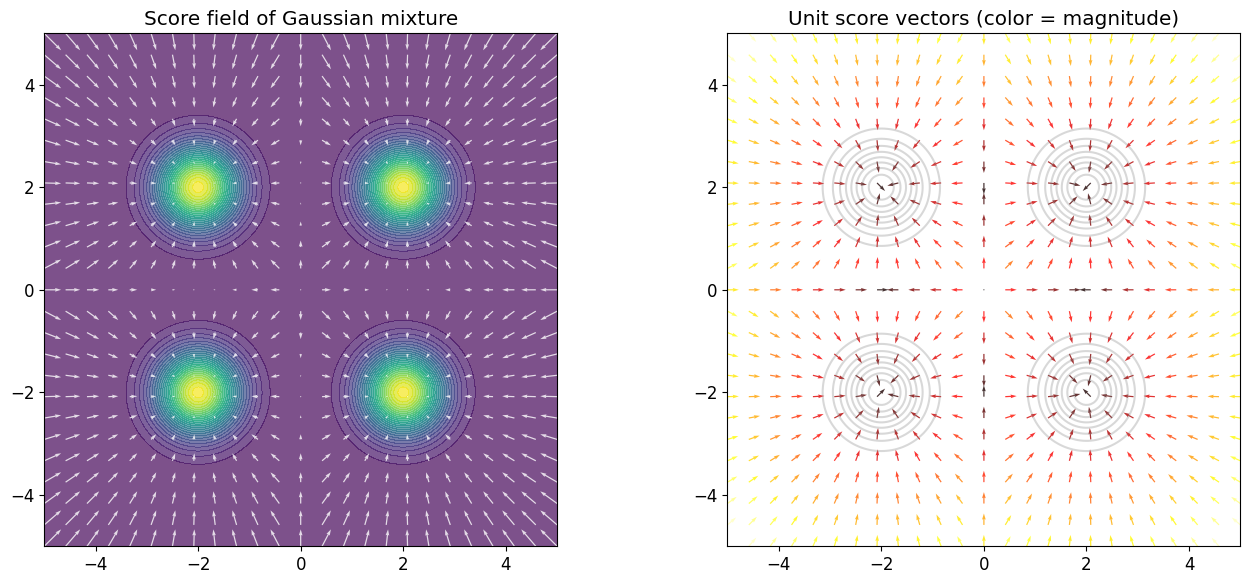

In [8]:
# Compute score of mixture using autograd
def mixture_log_prob_torch(x, params):
    """Compute log p(x) for a Gaussian mixture using PyTorch."""
    log_probs = []
    for p in params:
        mu = torch.tensor(p['mean'], dtype=torch.float32)
        cov = torch.tensor(p['cov'], dtype=torch.float32)
        w = p['weight']
        
        diff = x - mu
        cov_inv = torch.inverse(cov)
        # log N(x; mu, cov) = -0.5 * (x-mu)^T cov^{-1} (x-mu) - 0.5 * log|cov| - log(2pi)
        mahal = torch.sum(diff @ cov_inv * diff, dim=-1)
        log_det = torch.logdet(cov)
        log_p = -0.5 * mahal - 0.5 * log_det - np.log(2 * np.pi) + np.log(w)
        log_probs.append(log_p)
    
    # LogSumExp for numerical stability
    log_probs = torch.stack(log_probs, dim=-1)
    return torch.logsumexp(log_probs, dim=-1)

def mixture_score_autograd(points, params):
    """Compute score function of mixture using autograd."""
    points = points.clone().requires_grad_(True)
    log_p = mixture_log_prob_torch(points, params)
    log_p.sum().backward()
    return points.grad

# Compute score field
x_range = np.linspace(-5, 5, 25)
y_range = np.linspace(-5, 5, 25)
Xq, Yq = np.meshgrid(x_range, y_range)
pts = torch.tensor(np.stack([Xq.ravel(), Yq.ravel()], axis=1), dtype=torch.float32)

scores = mixture_score_autograd(pts, mixture_params)
Sx = scores[:, 0].numpy().reshape(Xq.shape)
Sy = scores[:, 1].numpy().reshape(Yq.shape)

# Also compute density for background
x_fine = np.linspace(-5, 5, 200)
y_fine = np.linspace(-5, 5, 200)
Xf, Yf = np.meshgrid(x_fine, y_fine)
pos_fine = np.dstack((Xf, Yf))
Z = mixture_pdf(pos_fine, mixture_params)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.contourf(Xf, Yf, Z, levels=30, cmap='viridis', alpha=0.7)
ax1.quiver(Xq, Yq, Sx, Sy, color='white', alpha=0.8)
ax1.set_title('Score field of Gaussian mixture')
ax1.set_aspect('equal')

# Show magnitude
score_mag = np.sqrt(Sx**2 + Sy**2)
ax2.quiver(Xq, Yq, Sx/(score_mag+1e-8), Sy/(score_mag+1e-8),
           score_mag, cmap='hot', alpha=0.8)
ax2.contour(Xf, Yf, Z, levels=10, colors='gray', alpha=0.3)
ax2.set_title('Unit score vectors (color = magnitude)')
ax2.set_aspect('equal')

plt.tight_layout()
plt.show()

**Notice**: Near each mode the score points at that mode, because its responsibility is close to 1. Between modes the responsibilities are split, and the score is a blend of "go to mode A" and "go to mode B". At the exact midpoint between two equal modes the two pulls cancel and the score is zero along the line joining them. That midpoint is a **saddle point** of $\log p$: a particle following the score exactly would sit there forever, which is one reason Langevin dynamics adds noise.

---
## 3. KL Divergence

The **Kullback-Leibler divergence** measures how different one probability distribution is from another:

$$D_{KL}(p \| q) = \int p(x) \log \frac{p(x)}{q(x)} dx = \mathbb{E}_p\left[\log \frac{p(x)}{q(x)}\right]$$

Key properties:
- $D_{KL} \geq 0$ (always non-negative)
- $D_{KL} = 0$ if and only if $p = q$
- **Not symmetric**: $D_{KL}(p \| q) \neq D_{KL}(q \| p)$ in general

In diffusion models, the ELBO (evidence lower bound) involves KL divergences between the forward and reverse process distributions at each timestep.

In [9]:
# KL divergence between two 1D Gaussians (analytical formula)
def kl_gaussian_1d(mu1, sigma1, mu2, sigma2):
    """D_KL(N(mu1, sigma1^2) || N(mu2, sigma2^2))"""
    return (np.log(sigma2/sigma1) + 
            (sigma1**2 + (mu1-mu2)**2) / (2*sigma2**2) - 0.5)

# Monte Carlo estimation of KL divergence
def kl_monte_carlo(samples_p, log_p_fn, log_q_fn):
    """Estimate D_KL(p || q) using samples from p."""
    return (log_p_fn(samples_p) - log_q_fn(samples_p)).mean()

# Compare analytical vs Monte Carlo
mu1, sigma1 = 0.0, 1.0
mu2, sigma2 = 1.0, 2.0

kl_exact = kl_gaussian_1d(mu1, sigma1, mu2, sigma2)

samples = np.random.normal(mu1, sigma1, 100000)
kl_mc = kl_monte_carlo(
    samples,
    lambda x: norm.logpdf(x, mu1, sigma1),
    lambda x: norm.logpdf(x, mu2, sigma2)
)

print(f"D_KL(N({mu1},{sigma1}^2) || N({mu2},{sigma2}^2)):")
print(f"  Analytical:   {kl_exact:.6f}")
print(f"  Monte Carlo:  {kl_mc:.6f}")
print(f"\nNote: D_KL is NOT symmetric:")
print(f"  D_KL(p || q) = {kl_exact:.6f}")
print(f"  D_KL(q || p) = {kl_gaussian_1d(mu2, sigma2, mu1, sigma1):.6f}")

D_KL(N(0.0,1.0^2) || N(1.0,2.0^2)):
  Analytical:   0.443147
  Monte Carlo:  0.439946

Note: D_KL is NOT symmetric:
  D_KL(p || q) = 0.443147
  D_KL(q || p) = 1.306853


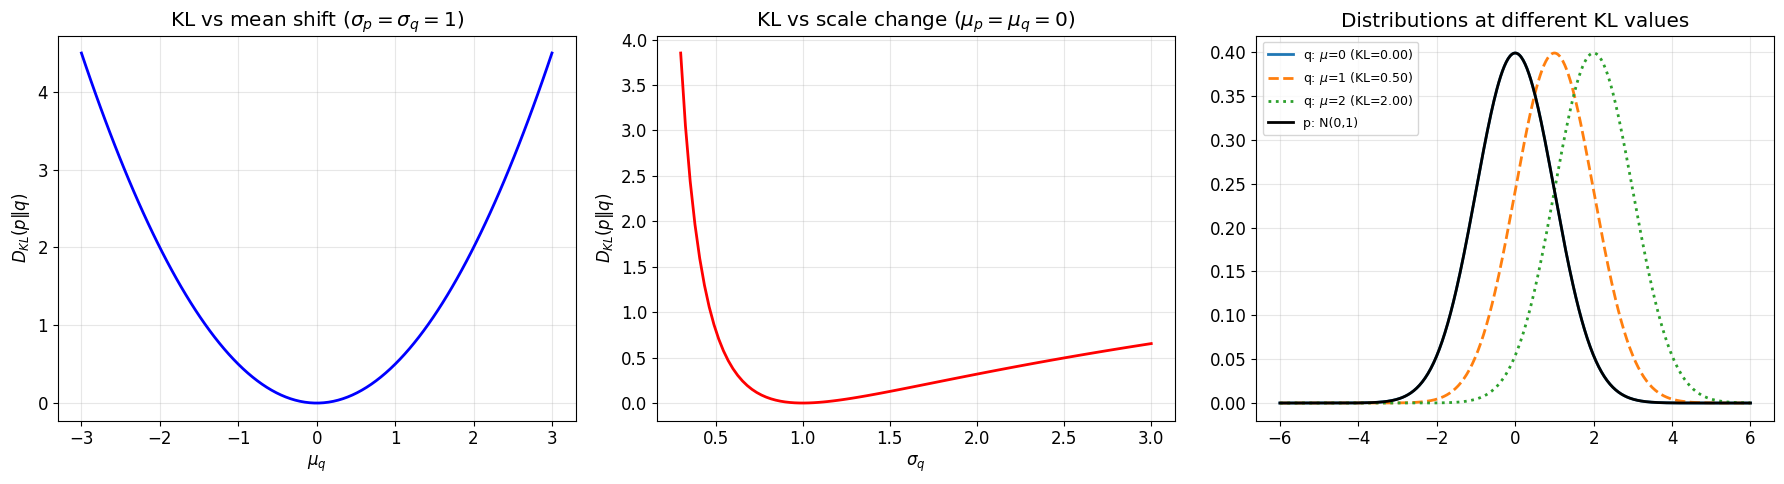

In [10]:
# Visualize KL divergence between a standard Gaussian and shifted versions
x = np.linspace(-6, 6, 500)
p = norm.pdf(x, 0, 1)  # reference: N(0, 1)

shifts = np.linspace(-3, 3, 100)
scales = np.linspace(0.3, 3, 100)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# KL vs mean shift
kl_shift = [kl_gaussian_1d(0, 1, mu, 1) for mu in shifts]
axes[0].plot(shifts, kl_shift, 'b-', linewidth=2)
axes[0].set_xlabel('$\\mu_q$'); axes[0].set_ylabel('$D_{KL}(p \\| q)$')
axes[0].set_title('KL vs mean shift ($\\sigma_p = \\sigma_q = 1$)')
axes[0].grid(True, alpha=0.3)

# KL vs scale
kl_scale = [kl_gaussian_1d(0, 1, 0, s) for s in scales]
axes[1].plot(scales, kl_scale, 'r-', linewidth=2)
axes[1].set_xlabel('$\\sigma_q$'); axes[1].set_ylabel('$D_{KL}(p \\| q)$')
axes[1].set_title('KL vs scale change ($\\mu_p = \\mu_q = 0$)')
axes[1].grid(True, alpha=0.3)

# Show the two distributions at different KL values
for mu_q, ls in [(0, '-'), (1, '--'), (2, ':')]:
    kl = kl_gaussian_1d(0, 1, mu_q, 1)
    q = norm.pdf(x, mu_q, 1)
    axes[2].plot(x, q, ls, linewidth=2, 
                 label=f'q: $\\mu$={mu_q} (KL={kl:.2f})')

axes[2].plot(x, p, 'k-', linewidth=2, label='p: N(0,1)')
axes[2].set_title('Distributions at different KL values')
axes[2].legend(fontsize=9); axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 3.1 Maximum likelihood = minimizing KL to the data

Fitting a model $p_\theta$ by **maximum likelihood** means maximizing $\mathbb{E}_{x\sim p_{\text{data}}}[\log p_\theta(x)]$. Expanding the KL divergence:

$$D_{KL}(p_{\text{data}} \,\|\, p_\theta) = \underbrace{\mathbb{E}_{p_{\text{data}}}[\log p_{\text{data}}(x)]}_{\text{constant in } \theta} - \mathbb{E}_{p_{\text{data}}}[\log p_\theta(x)]$$

So maximizing likelihood is exactly minimizing $D_{KL}(p_{\text{data}} \,\|\, p_\theta)$. This "forward" KL heavily penalises a model that assigns low probability to real data, which is why likelihood-trained models tend to **cover all modes** (sometimes too broadly).

### 3.2 The ELBO: a lower bound when $\log p_\theta(x)$ is intractable

Latent-variable models (VAEs in 0c; DDPM, where the "latents" are $x_1, \dots, x_T$) have $p_\theta(x) = \int p_\theta(x \mid z)\,p(z)\,dz$, which we can't evaluate. For **any** distribution $q(z)$:

$$\log p_\theta(x) = \underbrace{\mathbb{E}_{q}[\log p_\theta(x \mid z)] - D_{KL}(q(z) \,\|\, p(z))}_{\text{ELBO}(q)} \;+\; \underbrace{D_{KL}\big(q(z) \,\|\, p_\theta(z \mid x)\big)}_{\geq\, 0}$$

So the ELBO is a lower bound on $\log p_\theta(x)$, and the **gap is exactly the KL from $q$ to the true posterior**. Maximizing the ELBO over $q$ makes $q$ approximate the posterior; maximizing it over $\theta$ approximately maximizes likelihood.

- In a **VAE**, $q$ is the encoder $q_\phi(z \mid x)$.
- In **DDPM**, $q$ is the *fixed* forward noising process, and the ELBO decomposes into one KL term per timestep between $q(x_{t-1} \mid x_t, x_0)$ (section 1.4(c)) and the learned reverse step. With Gaussian reverse steps, each term reduces to a weighted MSE on $\epsilon$; Ho et al. dropped the weights to get the simple loss of notebook 1.

Let's check the identity on a model where everything is computable: $z \sim \mathcal{N}(0,1)$, $x \mid z \sim \mathcal{N}(z, s^2)$. Then $p(x) = \mathcal{N}(0, 1 + s^2)$ and $p(z \mid x) = \mathcal{N}\!\big(\tfrac{x}{1+s^2}, \tfrac{s^2}{1+s^2}\big)$.

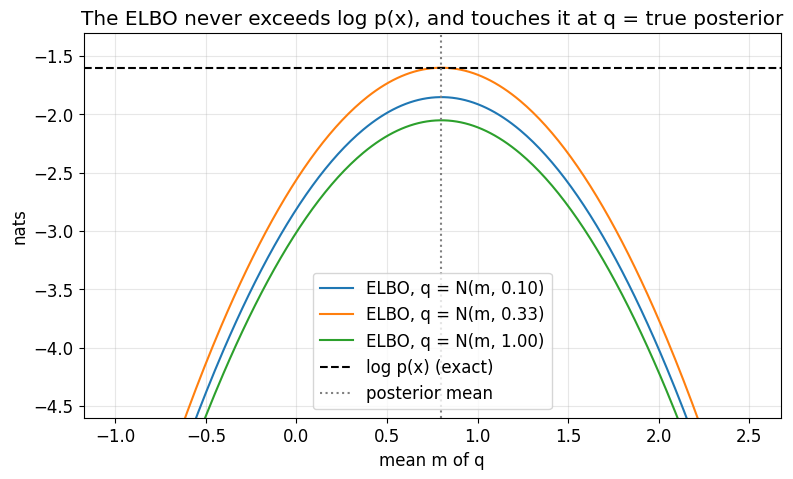

q = N(0.00, 1.00):  log p(x) - ELBO = 1.41069   KL(q || posterior) = 1.41069
q = N(1.00, 0.20):  log p(x) - ELBO = 0.11541   KL(q || posterior) = 0.11541
q = N(0.80, 0.33):  log p(x) - ELBO = 0.00000   KL(q || posterior) = 0.00000


In [11]:
s2, x_obs = 0.5, 1.2
log_px = norm.logpdf(x_obs, 0, np.sqrt(1 + s2))
post_m, post_v = x_obs / (1 + s2), s2 / (1 + s2)

def elbo(m, v):
    # ELBO for q(z) = N(m, v): E_q[log N(x; z, s2)] - KL(q || N(0,1)), both in closed form.
    expected_loglik = -0.5 * np.log(2 * np.pi * s2) - ((x_obs - m) ** 2 + v) / (2 * s2)
    kl_prior = 0.5 * (m ** 2 + v - 1 - np.log(v))
    return expected_loglik - kl_prior

def kl_gauss(m1, v1, m2, v2):
    return 0.5 * (np.log(v2 / v1) + (v1 + (m1 - m2) ** 2) / v2 - 1)

ms = np.linspace(-1, 2.5, 300)
plt.figure(figsize=(9, 5))
for v in [0.1, post_v, 1.0]:
    plt.plot(ms, [elbo(m, v) for m in ms], label=f'ELBO, q = N(m, {v:.2f})')
plt.axhline(log_px, color='k', ls='--', label='log p(x) (exact)')
plt.axvline(post_m, color='gray', ls=':', label='posterior mean')
plt.xlabel('mean m of q'); plt.ylabel('nats'); plt.ylim(log_px - 3, log_px + 0.3)
plt.title('The ELBO never exceeds log p(x), and touches it at q = true posterior')
plt.legend(); plt.grid(alpha=0.3); plt.show()

for m, v in [(0.0, 1.0), (1.0, 0.2), (post_m, post_v)]:
    print(f"q = N({m:.2f}, {v:.2f}):  log p(x) - ELBO = {log_px - elbo(m, v):.5f}   "
          f"KL(q || posterior) = {kl_gauss(m, v, post_m, post_v):.5f}")

---
## 4. Langevin Dynamics

**Langevin dynamics** is a method to sample from a distribution *using only its score function*. No need to know the normalizing constant!

The update rule:

$$\mathbf{x}_{t+1} = \mathbf{x}_t + \frac{\epsilon}{2} \nabla_\mathbf{x} \log p(\mathbf{x}_t) + \sqrt{\epsilon} \cdot \mathbf{z}_t, \quad \mathbf{z}_t \sim \mathcal{N}(0, I)$$

- The **score term** $\nabla_x \log p(x)$ pulls the sample toward high-probability regions
- The **noise term** $\sqrt{\epsilon} \cdot z$ prevents the sample from collapsing to a single point and ensures exploration
- As $\epsilon \to 0$ and $t \to \infty$, $x_t$ converges to a sample from $p(x)$

This is the conceptual ancestor of diffusion model sampling — if you know the score, you can sample!

In [12]:
def langevin_dynamics(score_fn, x_init, epsilon, n_steps, record_every=1):
    """
    Run Langevin dynamics sampling.
    
    score_fn: function(x) -> score vector
    x_init: (N, D) initial samples
    epsilon: step size
    n_steps: number of Langevin steps
    """
    x = x_init.clone()
    trajectory = [x.clone()]
    
    for i in range(n_steps):
        noise = torch.randn_like(x)
        score = score_fn(x)
        x = x + (epsilon / 2) * score + np.sqrt(epsilon) * noise
        if (i + 1) % record_every == 0:
            trajectory.append(x.clone())
    
    return x, trajectory

### 4.1 Sampling from a single Gaussian with Langevin dynamics

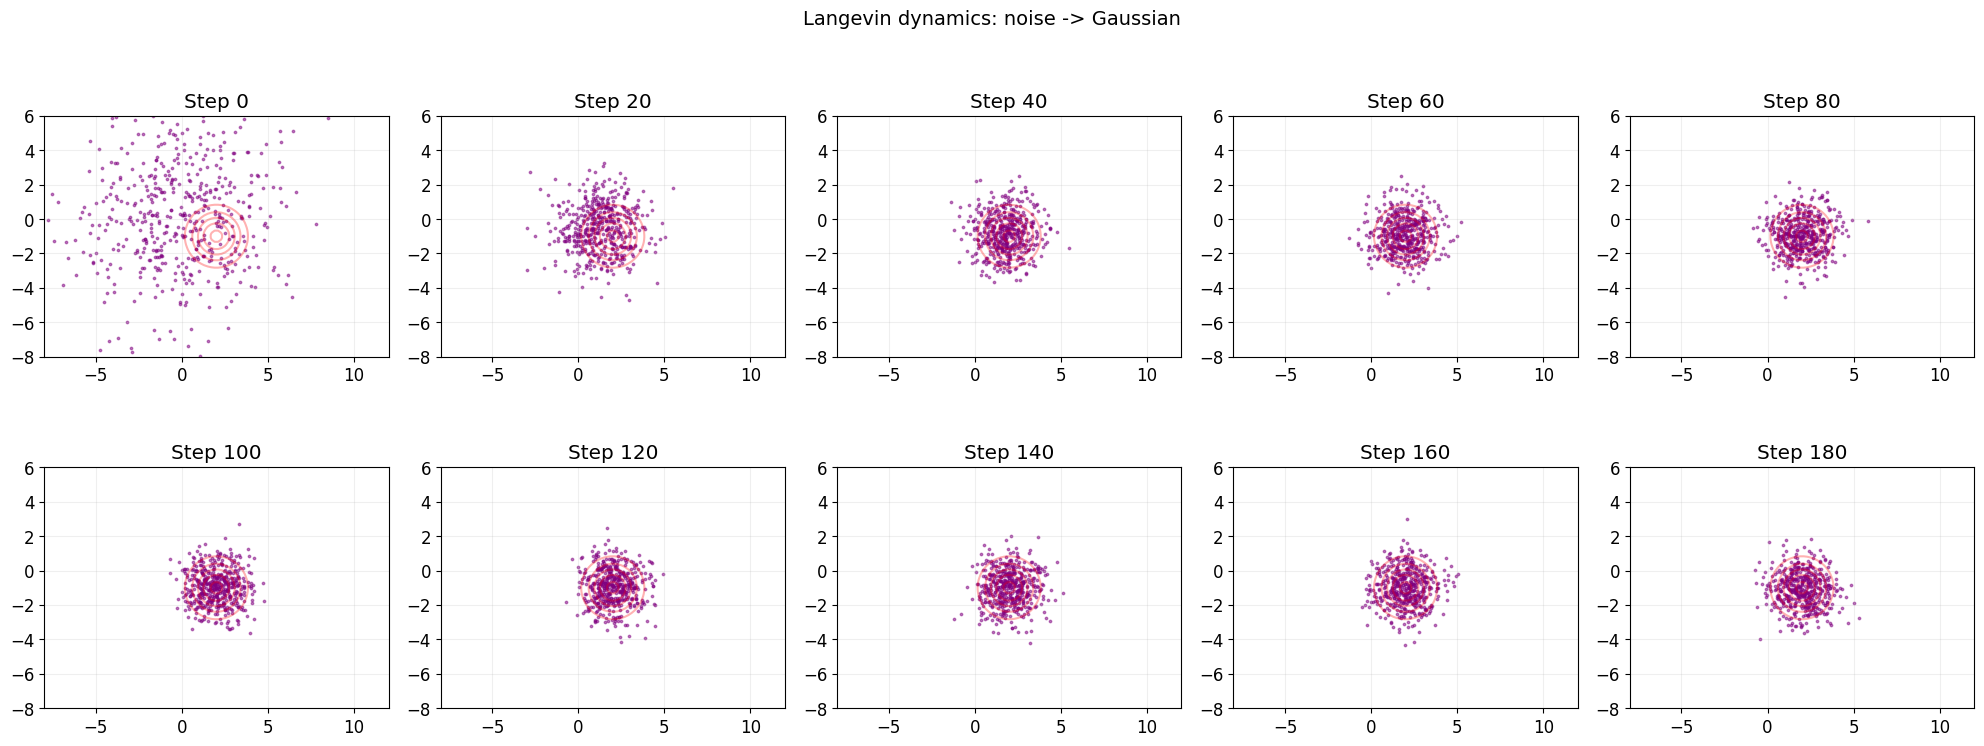

In [13]:
# Score function for N(mu, sigma^2*I) in 2D
mu_target = torch.tensor([2.0, -1.0])
sigma_target = 1.0

def gaussian_score(x):
    return -(x - mu_target) / sigma_target**2

# Start from random noise far from the mode
torch.manual_seed(42)
n_samples = 500
x_init = torch.randn(n_samples, 2) * 3  # overdispersed start

x_final, trajectory = langevin_dynamics(gaussian_score, x_init, epsilon=0.1, n_steps=200, record_every=20)

fig, axes = plt.subplots(2, 5, figsize=(20, 8))

# Draw target contours
x_grid = np.linspace(-8, 12, 100)
y_grid = np.linspace(-8, 6, 100)
Xg, Yg = np.meshgrid(x_grid, y_grid)
Zg = multivariate_normal(mu_target.numpy(), sigma_target**2 * np.eye(2)).pdf(np.dstack((Xg, Yg)))

for idx, ax in enumerate(axes.flat):
    if idx < len(trajectory):
        pts = trajectory[idx].numpy()
        ax.contour(Xg, Yg, Zg, levels=5, colors='red', alpha=0.3)
        ax.scatter(pts[:, 0], pts[:, 1], s=3, alpha=0.5, c='purple')
        ax.set_title(f'Step {idx * 20}')
        ax.set_xlim(-8, 12); ax.set_ylim(-8, 6)
        ax.set_aspect('equal')
        ax.grid(True, alpha=0.2)

plt.suptitle('Langevin dynamics: noise -> Gaussian', fontsize=14)
plt.tight_layout()
plt.show()

### 4.2 Sampling from a Gaussian mixture with Langevin dynamics

This is where it gets interesting — can Langevin dynamics handle multimodal distributions?

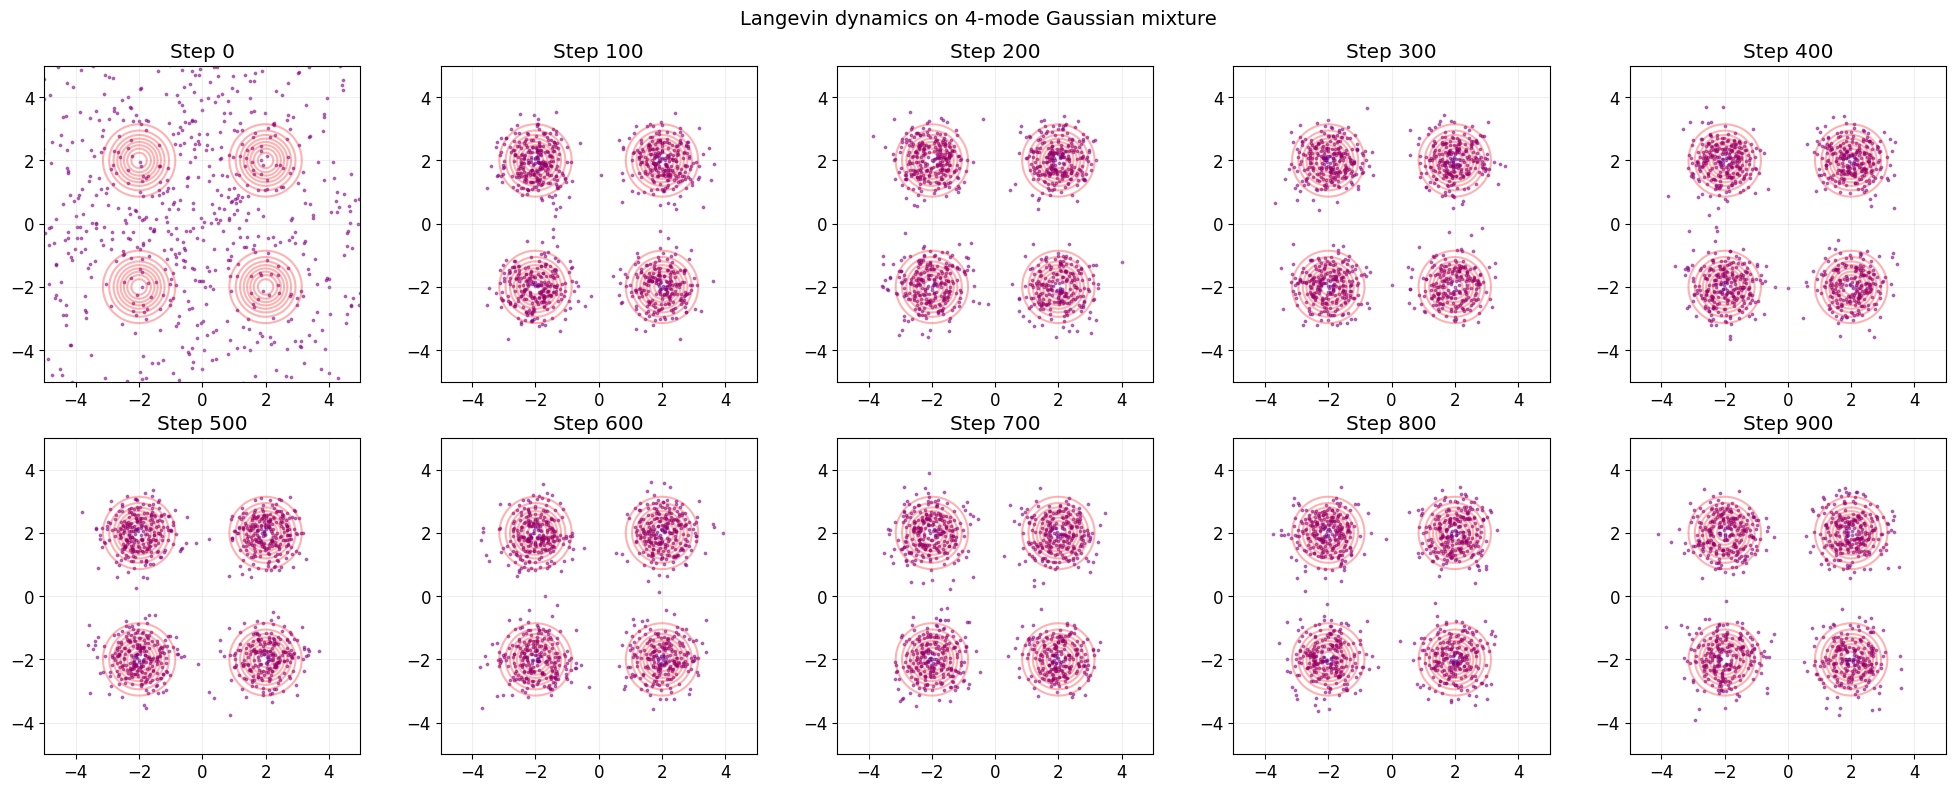

In [14]:
def mixture_score_fn(x):
    """Score function for the 4-component Gaussian mixture."""
    x = x.clone().requires_grad_(True)
    log_p = mixture_log_prob_torch(x, mixture_params)
    log_p.sum().backward()
    return x.grad.detach()

# Start from wide noise
torch.manual_seed(0)
x_init = torch.randn(1000, 2) * 4

x_final, trajectory = langevin_dynamics(mixture_score_fn, x_init, epsilon=0.05, n_steps=1000, record_every=100)

fig, axes = plt.subplots(2, 5, figsize=(20, 8))

for idx, ax in enumerate(axes.flat):
    if idx < len(trajectory):
        pts = trajectory[idx].numpy()
        ax.contour(Xf, Yf, Z, levels=10, colors='red', alpha=0.3)
        ax.scatter(pts[:, 0], pts[:, 1], s=3, alpha=0.5, c='purple')
        step = idx * 100
        ax.set_title(f'Step {step}')
        ax.set_xlim(-5, 5); ax.set_ylim(-5, 5)
        ax.set_aspect('equal')
        ax.grid(True, alpha=0.2)

plt.suptitle('Langevin dynamics on 4-mode Gaussian mixture', fontsize=14)
plt.tight_layout()
plt.show()

### 4.3 Tracking individual particles

Let's follow a few particles to see how Langevin dynamics explores the distribution.

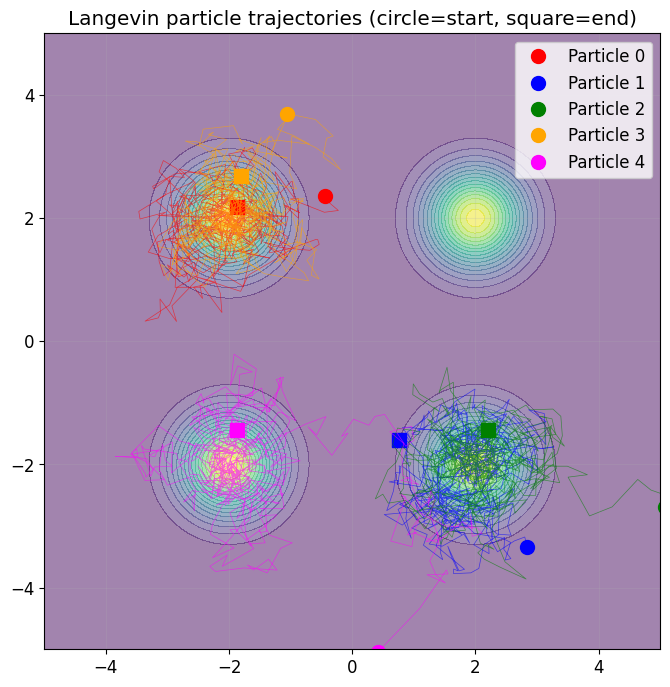

In [15]:
# Run Langevin on just a few particles, recording every step
torch.manual_seed(7)
x_init_few = torch.randn(5, 2) * 3

_, traj_few = langevin_dynamics(mixture_score_fn, x_init_few, epsilon=0.05, n_steps=500, record_every=1)

plt.figure(figsize=(8, 8))
plt.contourf(Xf, Yf, Z, levels=20, cmap='viridis', alpha=0.5)

colors = ['red', 'blue', 'green', 'orange', 'magenta']
for i in range(5):
    path = torch.stack([t[i] for t in traj_few]).numpy()
    plt.plot(path[:, 0], path[:, 1], '-', color=colors[i], alpha=0.6, linewidth=0.5)
    plt.plot(path[0, 0], path[0, 1], 'o', color=colors[i], markersize=10, label=f'Particle {i}')
    plt.plot(path[-1, 0], path[-1, 1], 's', color=colors[i], markersize=10)

plt.title('Langevin particle trajectories (circle=start, square=end)')
plt.legend(loc='upper right')
plt.xlim(-5, 5); plt.ylim(-5, 5)
plt.gca().set_aspect('equal')
plt.grid(True, alpha=0.2)
plt.show()

**Observation**: Particles are attracted to modes and then jitter around them. The noise term prevents them from settling at a single point. With enough steps, they can even jump between modes — though this becomes very unlikely when modes are far apart.

**Connection to diffusion**: This difficulty of jumping between modes at low noise levels is precisely why diffusion models use a *schedule* of noise levels. At high noise, the modes are smeared together and easy to navigate between. At low noise, the score function "sharpens" to point precisely toward the nearest mode.

### 4.4 The noise is not optional: the drift/noise balance

Why the specific pair $\frac{\epsilon}{2}\nabla\log p$ and $\sqrt{\epsilon}\,z$? Scale the noise by a factor $c$ and look at what the chain converges to. For a 1D standard Gaussian target ($\nabla \log p = -x$), the update is the linear recursion $x \leftarrow (1-\tfrac{\epsilon}{2})x + c\sqrt{\epsilon}\,z$, whose stationary variance is

$$\text{Var}_\infty = \frac{c^2\,\epsilon}{1 - (1-\epsilon/2)^2} = \frac{c^2}{1 - \epsilon/4} \;\xrightarrow{\;\epsilon \to 0\;}\; c^2$$

- $c = 0$: plain gradient ascent on $\log p$. Every particle collapses onto the mode, so you get an optimiser, not a sampler.
- $c < 1$: too cold, the samples are too concentrated.
- $c > 1$: too hot, the samples are too spread out.
- $c = 1$: the right distribution (up to an $O(\epsilon)$ discretisation bias, which Metropolis-adjusted Langevin removes).

This is the discrete analogue of the **fluctuation–dissipation relation** in physics (PHYSICS.md §3): the strength of the random kicks must match the strength of the restoring drift for the right equilibrium to emerge.

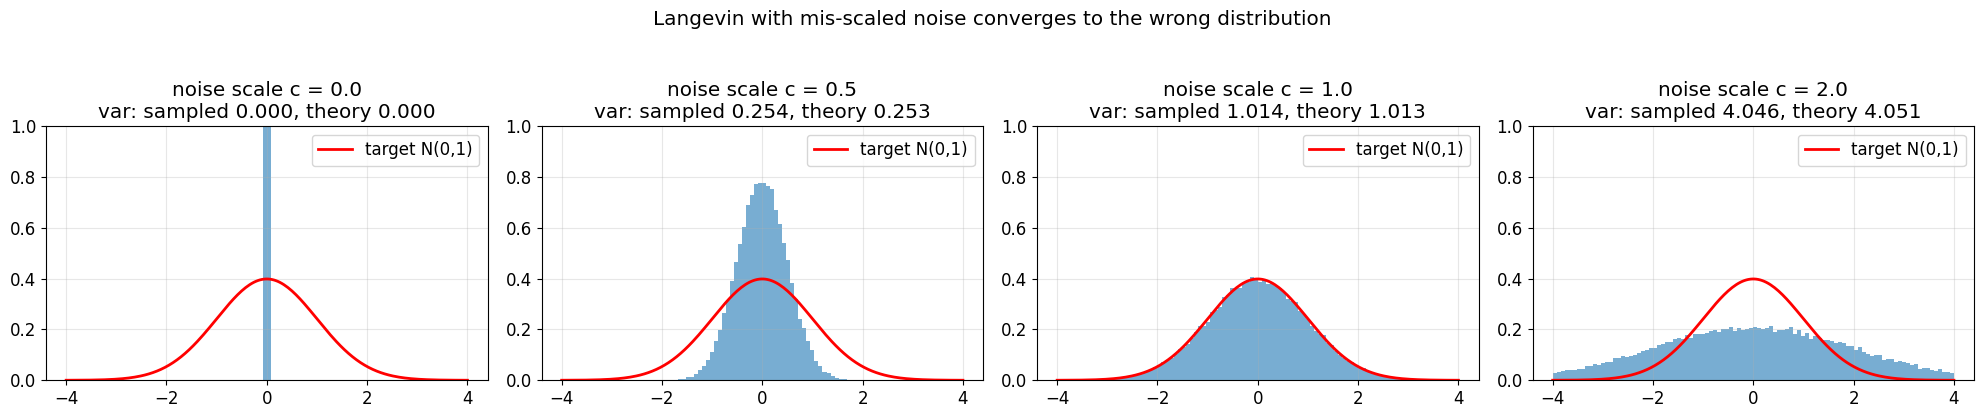

In [16]:
torch.manual_seed(0)
eps_step = 0.05
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
grid = np.linspace(-4, 4, 200)
for ax, c in zip(axes, [0.0, 0.5, 1.0, 2.0]):
    x = torch.randn(50000) * 3
    for _ in range(1500):
        x = x + eps_step / 2 * (-x) + c * np.sqrt(eps_step) * torch.randn_like(x)
    theory = c**2 / (1 - eps_step / 4)
    ax.hist(x.numpy(), bins=100, range=(-4, 4), density=True, alpha=0.6)
    ax.plot(grid, norm.pdf(grid), 'r-', lw=2, label='target N(0,1)')
    ax.set_title(f'noise scale c = {c}\nvar: sampled {x.var():.3f}, theory {theory:.3f}')
    ax.set_ylim(0, 1.0); ax.legend(); ax.grid(alpha=0.3)
plt.suptitle('Langevin with mis-scaled noise converges to the wrong distribution', y=1.04)
plt.tight_layout(); plt.show()

---
## 5. The Noising Process

Now let's see how adding Gaussian noise progressively destroys the structure of a distribution. This is the **forward diffusion process**.

If we start with data $x_0 \sim p_{\text{data}}$ and add noise:

$$x_t = \sqrt{\bar{\alpha}_t} \cdot x_0 + \sqrt{1 - \bar{\alpha}_t} \cdot \epsilon, \quad \epsilon \sim \mathcal{N}(0, I)$$

As $\bar{\alpha}_t \to 0$, the data signal vanishes and $x_t$ becomes pure noise.

**Two conventions you'll meet.** This is the *variance-preserving* (VP) form used by DDPM: the signal shrinks while noise is added, so $\text{Var}(x_t)$ stays near 1 for unit-variance data. Section 6 below (and Song & Ermon's NCSN) uses the *variance-exploding* (VE) form $x_\sigma = x_0 + \sigma\epsilon$: the signal is kept and the noise grows. They describe the same family of distributions up to rescaling. Dividing a VP sample by $\sqrt{\bar\alpha_t}$ gives

$$\frac{x_t}{\sqrt{\bar\alpha_t}} = x_0 + \underbrace{\sqrt{\tfrac{1-\bar\alpha_t}{\bar\alpha_t}}}_{\sigma_{\text{VE}}}\,\epsilon$$

So a VP noise level $t$ is the VE noise level $\sigma = \sqrt{(1-\bar\alpha_t)/\bar\alpha_t} = 1/\sqrt{\text{SNR}_t}$, viewed through a rescaled lens. 3b develops this "same path, different clocks" idea in full.

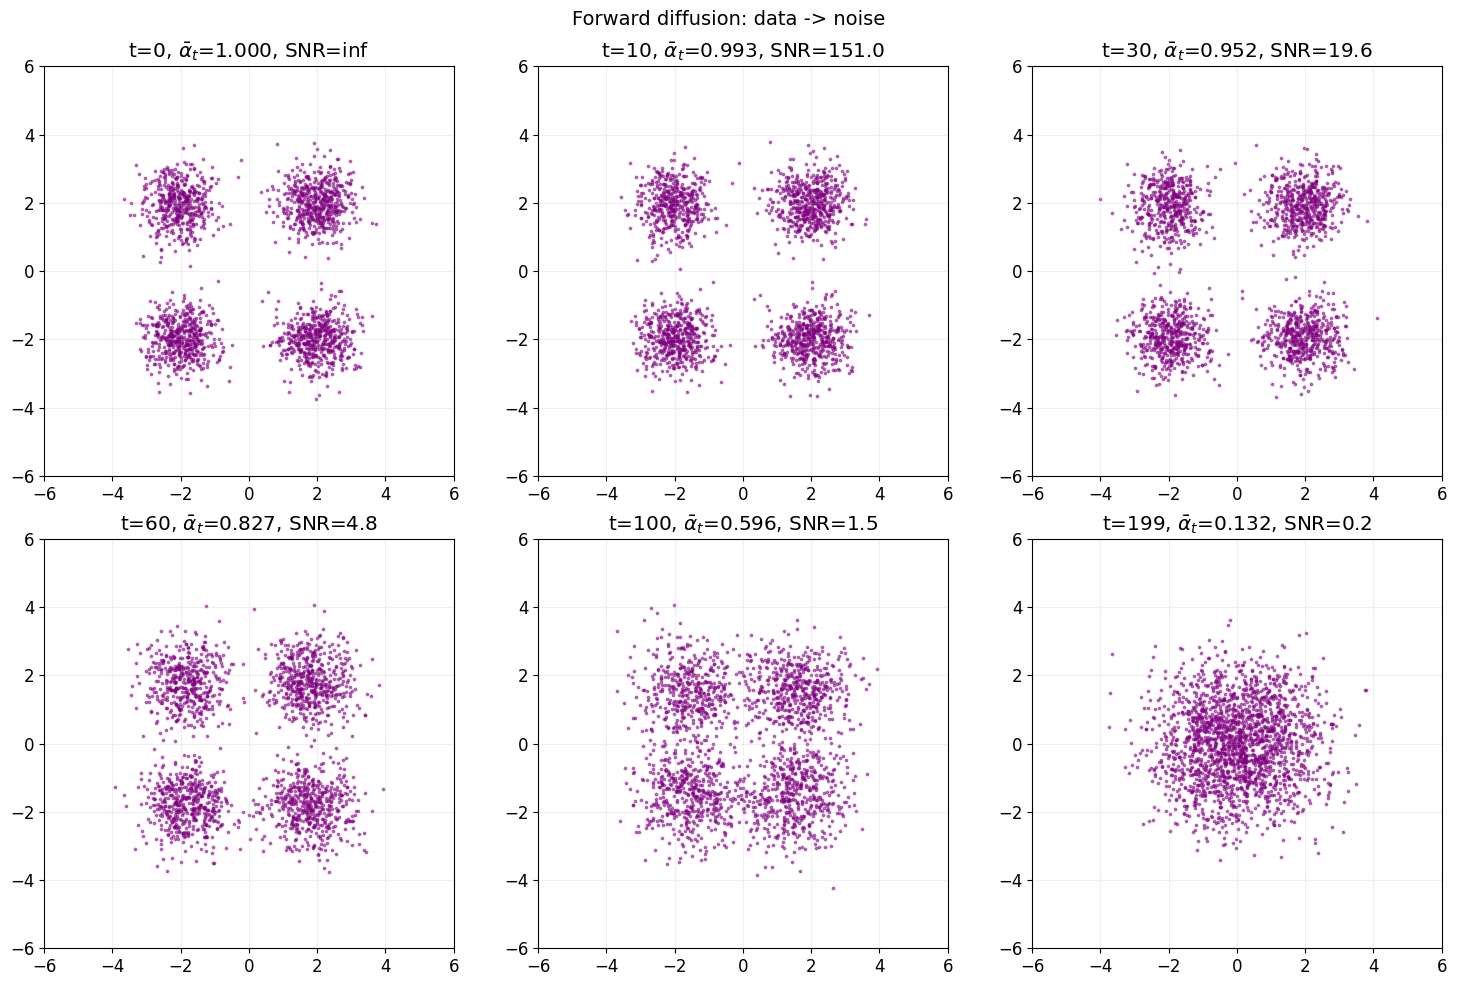

In [17]:
# Generate data from our 4-mode mixture
np.random.seed(42)
data = sample_mixture(mixture_params, 2000)
data_torch = torch.tensor(data, dtype=torch.float32)

# Define noise schedule
T = 200
betas = torch.linspace(1e-4, 0.02, T)
alphas = 1 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

# Visualize noising at different timesteps
timesteps_to_show = [0, 10, 30, 60, 100, 199]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for idx, (ax, t) in enumerate(zip(axes.flat, timesteps_to_show)):
    if t == 0:
        x_t = data_torch
    else:
        eps = torch.randn_like(data_torch)
        ab = alpha_bars[t]
        x_t = torch.sqrt(ab) * data_torch + torch.sqrt(1 - ab) * eps
    
    snr = alpha_bars[t].item() / (1 - alpha_bars[t].item()) if t > 0 else float('inf')
    
    ax.scatter(x_t[:, 0].numpy(), x_t[:, 1].numpy(), s=3, alpha=0.5, c='purple')
    ax.set_xlim(-6, 6); ax.set_ylim(-6, 6)
    ax.set_title(f't={t}, $\\bar{{\\alpha}}_t$={alpha_bars[min(t,T-1)]:.3f}, SNR={snr:.1f}')
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.2)

plt.suptitle('Forward diffusion: data -> noise', fontsize=14)
plt.tight_layout()
plt.show()

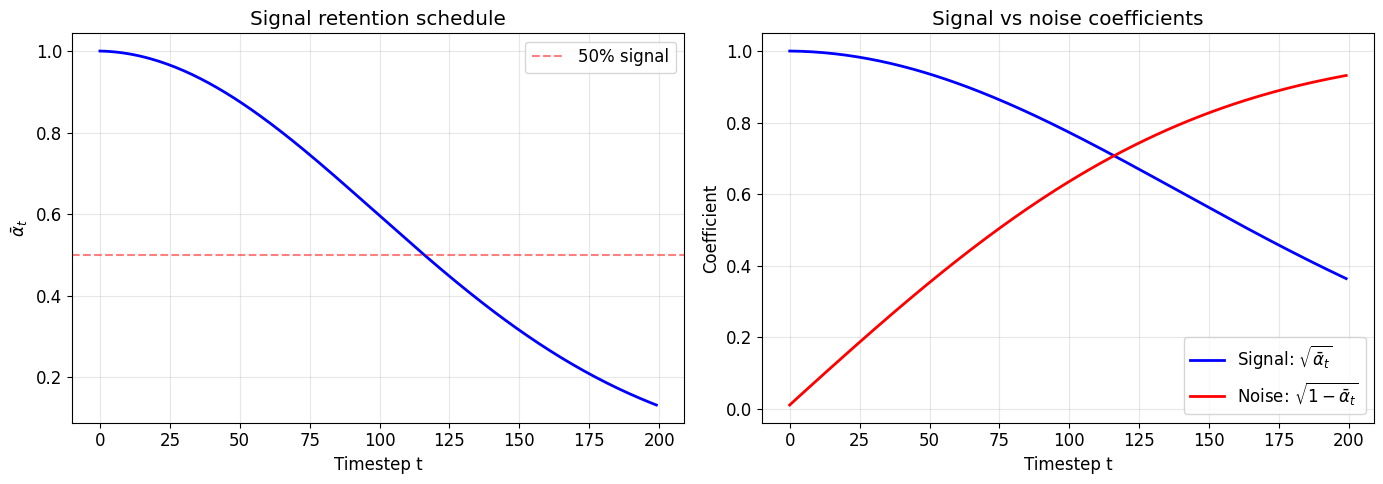

In [18]:
# Plot alpha_bar schedule
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(range(T), alpha_bars.numpy(), 'b-', linewidth=2)
ax1.set_xlabel('Timestep t')
ax1.set_ylabel('$\\bar{\\alpha}_t$')
ax1.set_title('Signal retention schedule')
ax1.axhline(y=0.5, color='r', linestyle='--', alpha=0.5, label='50% signal')
ax1.legend(); ax1.grid(True, alpha=0.3)

# Signal vs noise components
signal_strength = torch.sqrt(alpha_bars).numpy()
noise_strength = torch.sqrt(1 - alpha_bars).numpy()
ax2.plot(range(T), signal_strength, 'b-', linewidth=2, label='Signal: $\\sqrt{\\bar{\\alpha}_t}$')
ax2.plot(range(T), noise_strength, 'r-', linewidth=2, label='Noise: $\\sqrt{1-\\bar{\\alpha}_t}$')
ax2.set_xlabel('Timestep t')
ax2.set_ylabel('Coefficient')
ax2.set_title('Signal vs noise coefficients')
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 5.1 How the score function changes with noise level

This is the crucial insight: at high noise levels, the score function becomes smooth and easy to learn. At low noise levels, it becomes sharp and captures fine details.

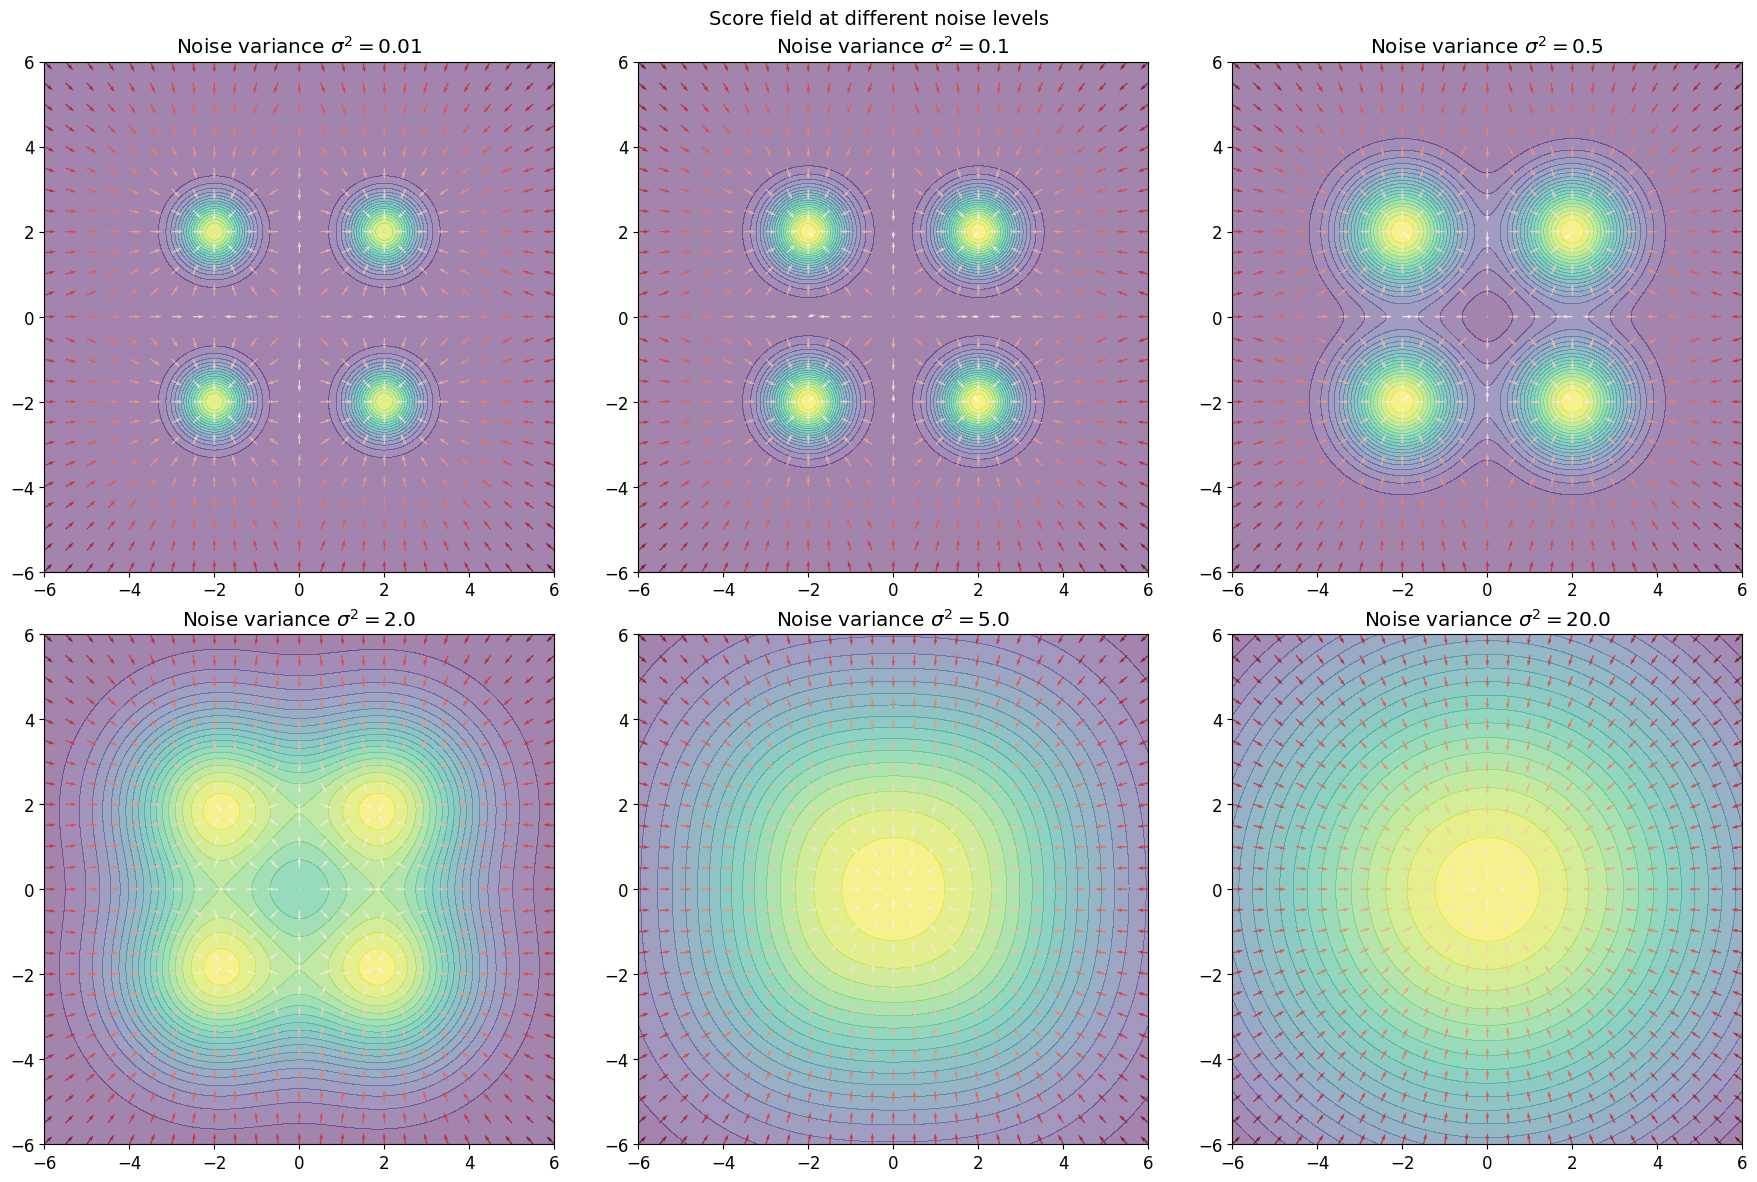

In [19]:
# Score of noised mixture at different noise levels
# At noise level sigma, the noised distribution is a convolution:
# p_sigma(x) = int N(x; x0, sigma^2 I) p_data(x0) dx0
# For a Gaussian mixture, this is just another Gaussian mixture with wider components

def noised_mixture_params(original_params, noise_var):
    """Parameters of the mixture after adding N(0, noise_var * I) noise."""
    noised = []
    for p in original_params:
        noised.append({
            'mean': p['mean'],
            'cov': [[p['cov'][0][0] + noise_var, p['cov'][0][1]],
                     [p['cov'][1][0], p['cov'][1][1] + noise_var]],
            'weight': p['weight']
        })
    return noised

noise_levels = [0.01, 0.1, 0.5, 2.0, 5.0, 20.0]

x_range = np.linspace(-6, 6, 25)
y_range = np.linspace(-6, 6, 25)
Xq, Yq = np.meshgrid(x_range, y_range)
pts = torch.tensor(np.stack([Xq.ravel(), Yq.ravel()], axis=1), dtype=torch.float32)

x_fine = np.linspace(-6, 6, 200)
y_fine = np.linspace(-6, 6, 200)
Xf, Yf = np.meshgrid(x_fine, y_fine)
pos_fine = np.dstack((Xf, Yf))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for ax, sigma2 in zip(axes.flat, noise_levels):
    noised_params = noised_mixture_params(mixture_params, sigma2)
    
    # Density
    Z_noised = mixture_pdf(pos_fine, noised_params)
    
    # Score
    scores = mixture_score_autograd(pts.clone(), noised_params)
    Sx = scores[:, 0].numpy().reshape(Xq.shape)
    Sy = scores[:, 1].numpy().reshape(Yq.shape)
    
    ax.contourf(Xf, Yf, Z_noised, levels=20, cmap='viridis', alpha=0.5)
    mag = np.sqrt(Sx**2 + Sy**2)
    ax.quiver(Xq, Yq, Sx/(mag+1e-8), Sy/(mag+1e-8), mag, cmap='Reds', alpha=0.8)
    ax.set_title(f'Noise variance $\\sigma^2 = {sigma2}$')
    ax.set_xlim(-6, 6); ax.set_ylim(-6, 6)
    ax.set_aspect('equal')

plt.suptitle('Score field at different noise levels', fontsize=14)
plt.tight_layout()
plt.show()

**This is the key insight of score-based diffusion models!**

- At **low noise** ($\sigma^2 = 0.01$): The score field is sharp and points precisely toward the nearest mode. Accurate near modes but hard to learn in low-density regions.
- At **high noise** ($\sigma^2 = 20$): The modes have merged into one blob. The score field is smooth and easy to learn everywhere, but contains no fine-grained structure.
- The diffusion model strategy: **learn the score at many noise levels**, then denoise from high to low noise, refining the structure at each step.

---
## 6. Denoising and Score Estimation

This section explains *why* training a network to predict noise teaches it the score. There are three steps.

### Step 1: MSE regression learns the conditional mean

If you fit $f(x)$ to minimise $\mathbb{E}\,\|f(x) - y\|^2$ over all functions, the minimiser is $f^*(x) = \mathbb{E}[y \mid x]$. The proof: for any $f$, $\mathbb{E}\|f(x)-y\|^2 = \mathbb{E}\|f(x) - \mathbb{E}[y\mid x]\|^2 + \mathbb{E}\|\mathbb{E}[y\mid x] - y\|^2$, and the second term doesn't depend on $f$. So a DDPM network trained on $\|\epsilon_\theta(x_t,t) - \epsilon\|^2$ converges to $\epsilon_\theta(x_t,t) = \mathbb{E}[\epsilon \mid x_t]$, the *average* noise consistent with what it sees. It does **not** learn the actual noise of each sample, which is unknowable. That is also why the training loss never reaches zero.

### Step 2: Tweedie's formula, the conditional mean IS the score

Let $x_\sigma = x_0 + \sigma\epsilon$ with $\epsilon \sim \mathcal{N}(0, I)$, so $p_\sigma(x) = \int p_{\text{data}}(x_0)\,\mathcal{N}(x;\, x_0,\, \sigma^2 I)\,dx_0$. Differentiate under the integral, using $\nabla_x \mathcal{N}(x; x_0, \sigma^2 I) = -\frac{x - x_0}{\sigma^2}\mathcal{N}(x; x_0, \sigma^2 I)$:

$$\nabla_x \log p_\sigma(x) = \frac{\nabla_x p_\sigma(x)}{p_\sigma(x)} = -\frac{1}{\sigma^2}\,\frac{\int (x - x_0)\, p_{\text{data}}(x_0)\,\mathcal{N}(x; x_0, \sigma^2 I)\,dx_0}{p_\sigma(x)} = \frac{\mathbb{E}[x_0 \mid x_\sigma = x] - x}{\sigma^2}$$

Using $\mathbb{E}[\epsilon \mid x_\sigma] = (x - \mathbb{E}[x_0 \mid x_\sigma])/\sigma$, this is equivalently

$$\boxed{\;\nabla_x \log p_\sigma(x) = -\frac{\mathbb{E}[\epsilon \mid x_\sigma = x]}{\sigma}\;}$$

The **optimal denoiser points along the score**: the score is the direction from $x$ to its best clean guess, divided by $\sigma^2$. For DDPM's VP noising $x_t = \sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$ the same argument gives $\nabla \log p_t(x_t) = -\mathbb{E}[\epsilon\mid x_t]/\sqrt{1-\bar\alpha_t}$.

### Step 3: Denoising score matching

Combining steps 1 and 2: regressing on the per-sample target $-\epsilon/\sigma$, the score of the *conditional* $p(x_\sigma \mid x_0)$, recovers the score of the *marginal* $p_\sigma$, since

$$\mathbb{E}\,\Big\|s_\theta(x_\sigma) + \frac{\epsilon}{\sigma}\Big\|^2 = \mathbb{E}\,\big\|s_\theta(x_\sigma) - \nabla \log p_\sigma(x_\sigma)\big\|^2 + \text{const}$$

This is **denoising score matching** (Vincent, 2011). We never need the marginal score itself, only the noise we added. The flow-matching loss (notebook 4, 3b) is the same trick applied to velocities.

Let's verify steps 1 and 2 numerically.

In [20]:
# For a simple Gaussian: x0 ~ N(mu, sigma_data^2), noise ~ N(0, sigma_noise^2)
# x_t = x0 + sigma_noise * eps
# Then x_t ~ N(mu, sigma_data^2 + sigma_noise^2)
# Score: -(x_t - mu) / (sigma_data^2 + sigma_noise^2)
# Optimal denoiser: E[x0 | xt] = mu + sigma_data^2/(sigma_data^2 + sigma_noise^2) * (xt - mu)
# (E[x0|xt] - xt) / sigma_noise^2 = -(xt - mu)/(sigma_data^2 + sigma_noise^2) = score!

mu_data = 2.0
sigma_data = 1.0
sigma_noise = 1.5

# Generate noisy samples
torch.manual_seed(42)
n = 10000
x0 = mu_data + sigma_data * torch.randn(n)
eps = torch.randn(n)
xt = x0 + sigma_noise * eps

# For a specific xt value, compute the score two ways
xt_test = torch.tensor(3.5)

# Method 1: Analytical score of p(xt)
total_var = sigma_data**2 + sigma_noise**2
score_analytical = -(xt_test - mu_data) / total_var

# Method 2: From optimal denoising
# E[x0 | xt] = mu + sigma_data^2/total_var * (xt - mu)
E_x0_given_xt = mu_data + sigma_data**2 / total_var * (xt_test - mu_data)
score_from_denoising = (E_x0_given_xt - xt_test) / sigma_noise**2

print(f"At xt = {xt_test.item():.1f}:")
print(f"  Score (analytical):      {score_analytical.item():.6f}")
print(f"  Score (from denoising):  {score_from_denoising.item():.6f}")
print(f"  They match! Denoising = Score estimation")

At xt = 3.5:
  Score (analytical):      -0.461538
  Score (from denoising):  -0.461538
  They match! Denoising = Score estimation


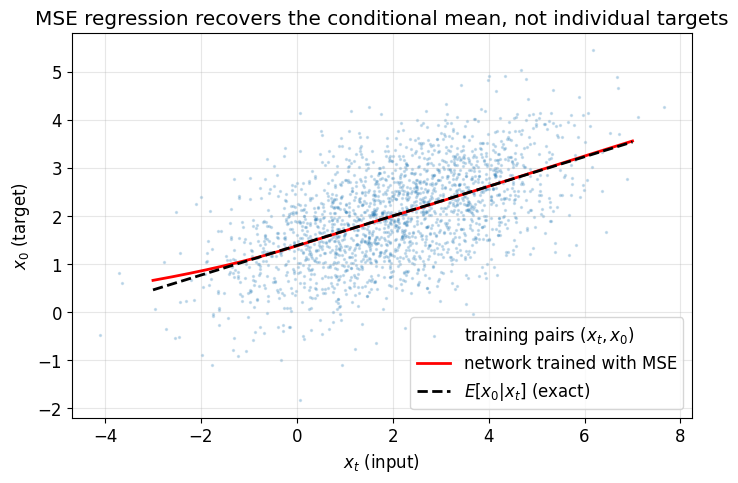

training MSE (mean of last 1000 steps) = 0.694; irreducible floor = Var(x0|xt) = 0.692


In [21]:
# Step 1 in action: a network trained with MSE to predict x0 from xt converges to E[x0 | xt]
torch.manual_seed(0)
reg = nn.Sequential(nn.Linear(1, 64), nn.SiLU(), nn.Linear(64, 64), nn.SiLU(), nn.Linear(64, 1))
opt_reg = torch.optim.Adam(reg.parameters(), lr=3e-3)
reg_losses = []
for _ in range(3000):
    x0_b = mu_data + sigma_data * torch.randn(512, 1)
    xt_b = x0_b + sigma_noise * torch.randn(512, 1)
    loss = ((reg(xt_b) - x0_b) ** 2).mean()           # regress the CLEAN value from the noisy one
    opt_reg.zero_grad(); loss.backward(); opt_reg.step()
    reg_losses.append(loss.item())

xs = torch.linspace(-3, 7, 200).unsqueeze(1)
with torch.no_grad():
    learned = reg(xs).squeeze()
exact_cond_mean = mu_data + sigma_data**2 / (sigma_data**2 + sigma_noise**2) * (xs.squeeze() - mu_data)

plt.figure(figsize=(8, 5))
plt.scatter(xt[:2000], x0[:2000], s=2, alpha=0.2, label='training pairs $(x_t, x_0)$')
plt.plot(xs, learned, 'r-', lw=2, label='network trained with MSE')
plt.plot(xs, exact_cond_mean, 'k--', lw=2, label='$E[x_0 | x_t]$ (exact)')
plt.xlabel('$x_t$ (input)'); plt.ylabel('$x_0$ (target)'); plt.legend(); plt.grid(alpha=0.3)
plt.title('MSE regression recovers the conditional mean, not individual targets')
plt.show()
print(f"training MSE (mean of last 1000 steps) = {np.mean(reg_losses[-1000:]):.3f}; irreducible floor = Var(x0|xt) = "
      f"{sigma_data**2 * sigma_noise**2 / (sigma_data**2 + sigma_noise**2):.3f}")

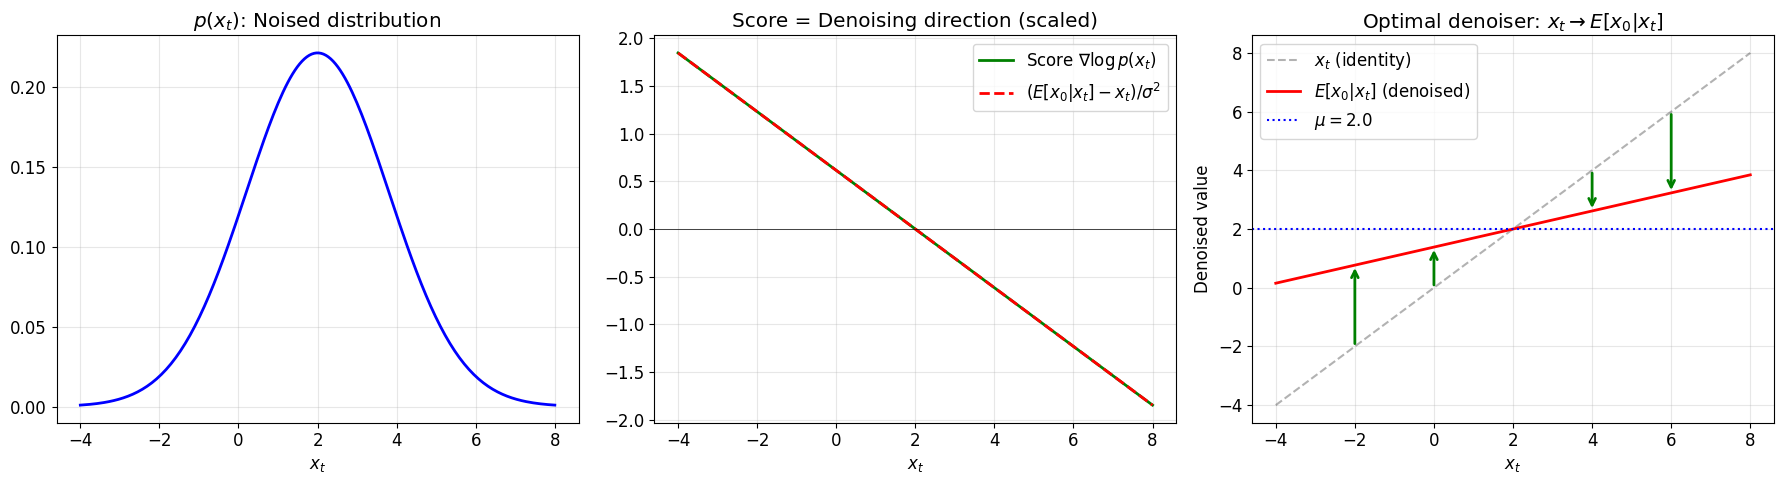

In [22]:
# Visualize the relationship
x_range = np.linspace(-4, 8, 200)

total_var = sigma_data**2 + sigma_noise**2
score = -(x_range - mu_data) / total_var
E_x0 = mu_data + sigma_data**2 / total_var * (x_range - mu_data)
denoising_direction = E_x0 - x_range  # points from xt toward E[x0|xt]

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# p(xt)
ax1.plot(x_range, norm.pdf(x_range, mu_data, np.sqrt(total_var)), 'b-', linewidth=2)
ax1.set_title('$p(x_t)$: Noised distribution')
ax1.set_xlabel('$x_t$'); ax1.grid(True, alpha=0.3)

# Score function
ax2.plot(x_range, score, 'g-', linewidth=2, label='Score $\\nabla \\log p(x_t)$')
ax2.plot(x_range, denoising_direction / sigma_noise**2, 'r--', linewidth=2,
         label='$(E[x_0|x_t] - x_t) / \\sigma^2$')
ax2.axhline(y=0, color='k', linewidth=0.5)
ax2.set_title('Score = Denoising direction (scaled)')
ax2.set_xlabel('$x_t$'); ax2.legend(); ax2.grid(True, alpha=0.3)

# Denoising visualization  
ax3.plot(x_range, x_range, 'k--', alpha=0.3, label='$x_t$ (identity)')
ax3.plot(x_range, E_x0, 'r-', linewidth=2, label='$E[x_0 | x_t]$ (denoised)')
ax3.axhline(y=mu_data, color='blue', linestyle=':', label=f'$\\mu = {mu_data}$')
# Draw arrows showing the denoising direction
for xt_val in [-2, 0, 2, 4, 6]:
    e_x0 = mu_data + sigma_data**2 / total_var * (xt_val - mu_data)
    ax3.annotate('', xy=(xt_val, e_x0), xytext=(xt_val, xt_val),
                arrowprops=dict(arrowstyle='->', color='green', lw=2))
ax3.set_xlabel('$x_t$'); ax3.set_ylabel('Denoised value')
ax3.set_title('Optimal denoiser: $x_t \\to E[x_0|x_t]$')
ax3.legend(); ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 6.1 Training a tiny denoiser (preview of DDPM)

Let's train a small network to predict the noise $\epsilon$ added to our mixture data, exactly like notebook 1 does for the spiral.

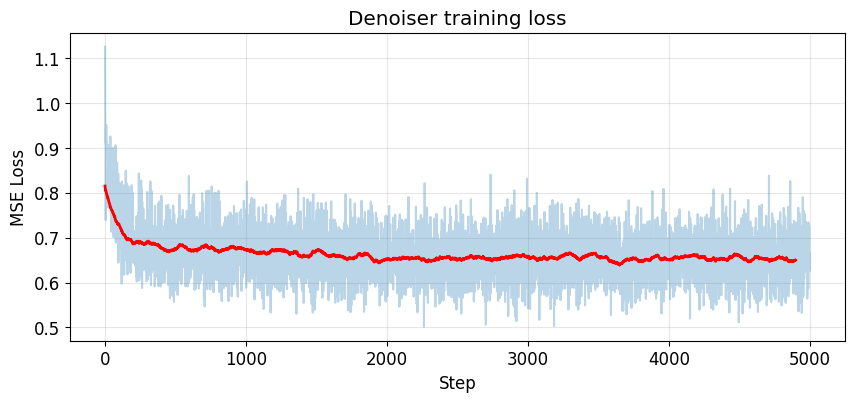

In [23]:
class SimpleDenoiser(nn.Module):
    """Predicts noise eps given noisy sample xt and noise level sigma."""
    def __init__(self, data_dim=2, hidden_dim=128):
        super().__init__()
        # Input: (xt, sigma) -> concatenated
        self.net = nn.Sequential(
            nn.Linear(data_dim + 1, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, data_dim),
        )
    
    def forward(self, xt, sigma):
        # sigma can be a scalar or a (batch, 1) tensor
        if sigma.dim() == 0:
            sigma = sigma.expand(xt.shape[0], 1)
        elif sigma.dim() == 1:
            sigma = sigma.unsqueeze(1)
        inp = torch.cat([xt, sigma], dim=1)
        return self.net(inp)

# Training
model = SimpleDenoiser().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

data_tensor = torch.tensor(data, dtype=torch.float32).to(device)
sigma_min, sigma_max = 0.1, 3.0

losses = []
for step in range(5000):
    # Sample random data points
    idx = torch.randint(0, len(data_tensor), (256,))
    x0 = data_tensor[idx]
    
    # Sample random noise level (log-uniform)
    log_sigma = torch.rand(256, device=device) * (np.log(sigma_max) - np.log(sigma_min)) + np.log(sigma_min)
    sigma = torch.exp(log_sigma)
    
    # Add noise
    eps = torch.randn_like(x0)
    xt = x0 + sigma.unsqueeze(1) * eps
    
    # Predict noise
    eps_pred = model(xt, sigma)
    loss = ((eps_pred - eps)**2).mean()
    
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

plt.figure(figsize=(10, 4))
plt.plot(losses, alpha=0.3)
plt.plot(np.convolve(losses, np.ones(100)/100, mode='valid'), 'r-', linewidth=2)
plt.xlabel('Step'); plt.ylabel('MSE Loss')
plt.title('Denoiser training loss')
plt.grid(True, alpha=0.3)
plt.show()

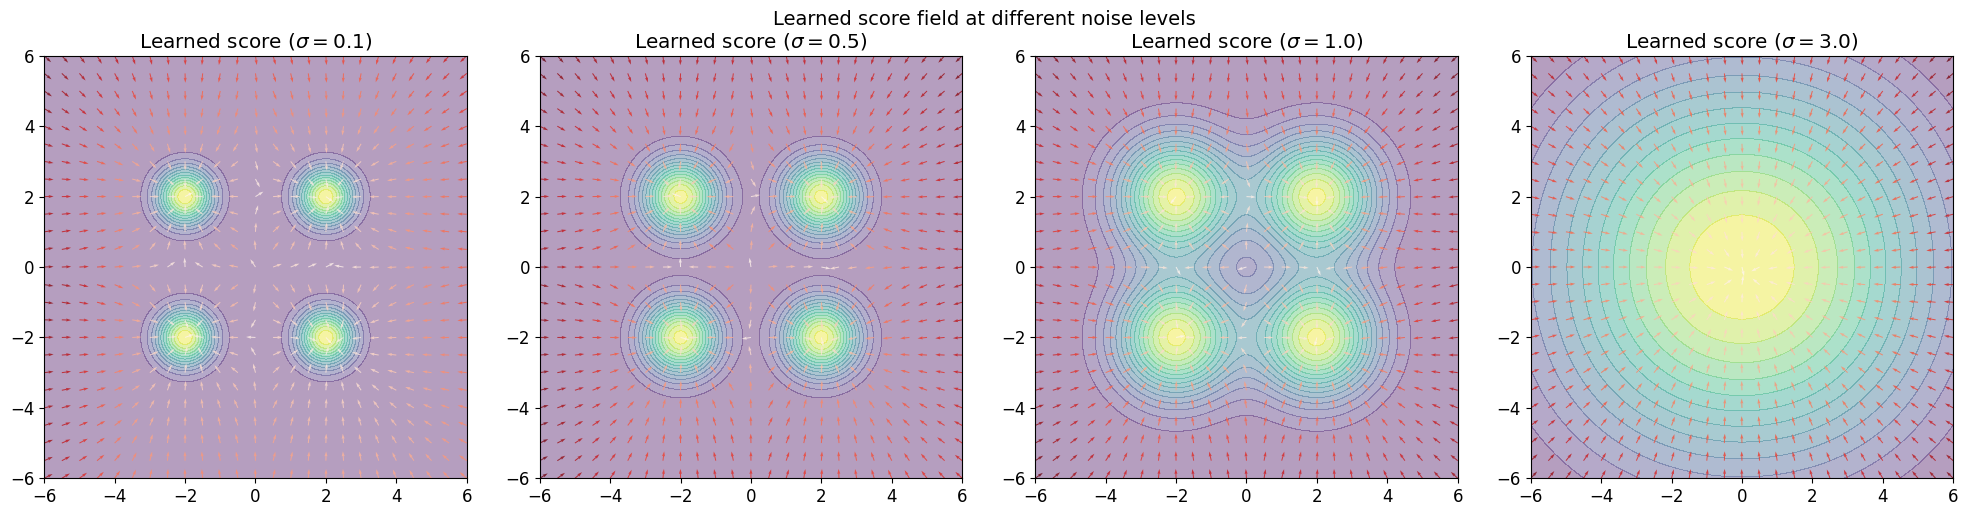

In [24]:
# Visualize the learned score field at different noise levels
# score = -eps_pred / sigma

model.eval()
x_range = np.linspace(-6, 6, 25)
y_range = np.linspace(-6, 6, 25)
Xq, Yq = np.meshgrid(x_range, y_range)
grid_pts = torch.tensor(np.stack([Xq.ravel(), Yq.ravel()], axis=1), dtype=torch.float32).to(device)

noise_levels_viz = [0.1, 0.5, 1.0, 3.0]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, sigma_val in zip(axes, noise_levels_viz):
    sigma_tensor = torch.full((grid_pts.shape[0],), sigma_val, device=device)
    
    with torch.no_grad():
        eps_pred = model(grid_pts, sigma_tensor)
    
    # Learned score = -eps_pred / sigma
    learned_score = (-eps_pred / sigma_val).cpu().numpy()
    Sx = learned_score[:, 0].reshape(Xq.shape)
    Sy = learned_score[:, 1].reshape(Yq.shape)
    
    # Background: noised density
    noised = noised_mixture_params(mixture_params, sigma_val**2)
    x_f = np.linspace(-6, 6, 200)
    y_f = np.linspace(-6, 6, 200)
    Xf2, Yf2 = np.meshgrid(x_f, y_f)
    Z_bg = mixture_pdf(np.dstack((Xf2, Yf2)), noised)
    
    ax.contourf(Xf2, Yf2, Z_bg, levels=15, cmap='viridis', alpha=0.4)
    mag = np.sqrt(Sx**2 + Sy**2)
    ax.quiver(Xq, Yq, Sx/(mag+1e-8), Sy/(mag+1e-8), mag, cmap='Reds', alpha=0.8)
    ax.set_title(f'Learned score ($\\sigma={sigma_val}$)')
    ax.set_xlim(-6, 6); ax.set_ylim(-6, 6)
    ax.set_aspect('equal')

plt.suptitle('Learned score field at different noise levels', fontsize=14)
plt.tight_layout()
plt.show()

### 6.1b How good is the learned score?

The pictures look right, but we can do better than eyeballing: the noised mixture has an exact score (section 5.1), so we can measure the error of the learned score $-\epsilon_\theta/\sigma$ at points drawn from $p_\sigma$, where the sampler will actually go.

sigma =  0.1:  mean |s_learned - s_exact| / mean |s_exact| = 0.436
sigma =  0.2:  mean |s_learned - s_exact| / mean |s_exact| = 0.199
sigma =  0.5:  mean |s_learned - s_exact| / mean |s_exact| = 0.129
sigma =  1.0:  mean |s_learned - s_exact| / mean |s_exact| = 0.101
sigma =  2.0:  mean |s_learned - s_exact| / mean |s_exact| = 0.075
sigma =  3.0:  mean |s_learned - s_exact| / mean |s_exact| = 0.057


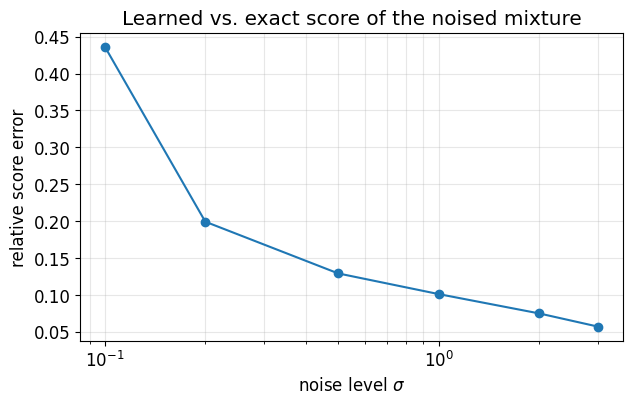

In [25]:
rel_errors = []
sig_list = [0.1, 0.2, 0.5, 1.0, 2.0, 3.0]
for sigma_val in sig_list:
    torch.manual_seed(1)
    x0_eval = data_tensor[torch.randint(0, len(data_tensor), (2000,))]
    xt_eval = x0_eval + sigma_val * torch.randn_like(x0_eval)
    with torch.no_grad():
        s_learned = -model(xt_eval, torch.full((len(xt_eval),), sigma_val, device=device)) / sigma_val
    s_exact = mixture_score_autograd(xt_eval.cpu().float(), noised_mixture_params(mixture_params, sigma_val**2))
    err = (s_learned.cpu() - s_exact).norm(dim=1).mean() / s_exact.norm(dim=1).mean()
    rel_errors.append(err.item())
    print(f"sigma = {sigma_val:4.1f}:  mean |s_learned - s_exact| / mean |s_exact| = {err:.3f}")

plt.figure(figsize=(7, 4))
plt.semilogx(sig_list, rel_errors, 'o-')
plt.xlabel('noise level $\\sigma$'); plt.ylabel('relative score error')
plt.title('Learned vs. exact score of the noised mixture'); plt.grid(alpha=0.3, which='both')
plt.show()

The error is typically largest at the **smallest** noise levels: there the score is large and changes sharply near each blob, and the $\epsilon$-target is very noisy relative to its mean. This is one motivation for the loss weightings and parameterizations (predict $x_0$, predict $v$, EDM preconditioning) discussed in THEORY.md §7–8.

### 6.2 Generating samples using the learned score

We can use our learned denoiser to generate new samples by running Langevin dynamics at decreasing noise levels — this is essentially what DDPM sampling does!

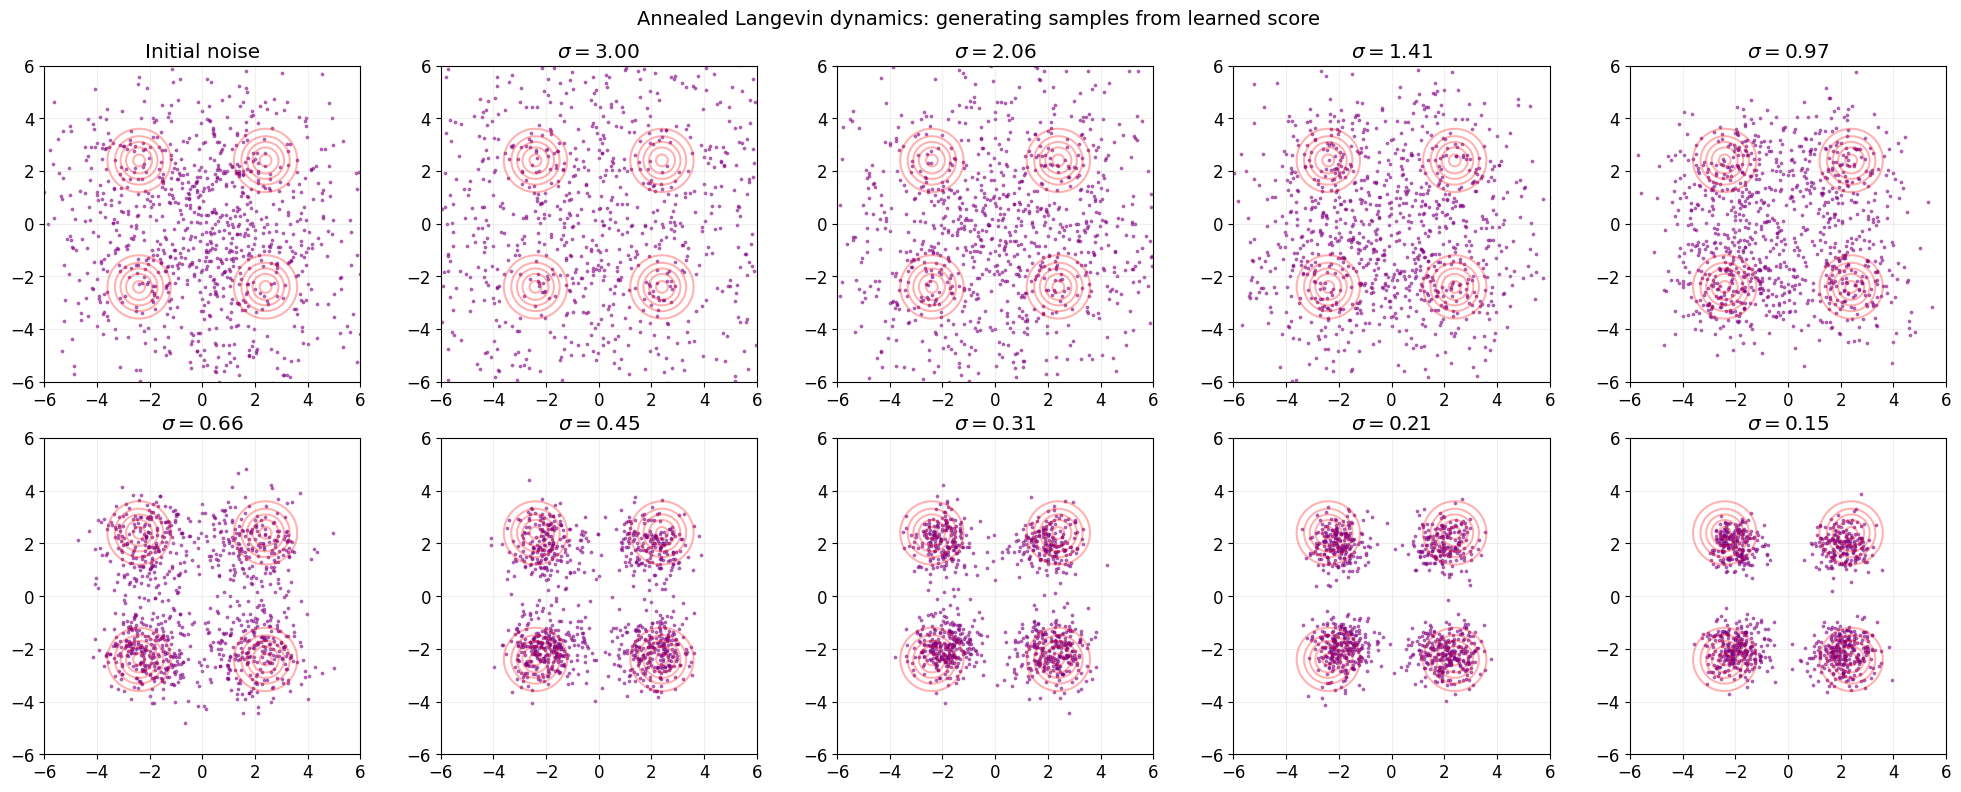

In [26]:
@torch.no_grad()
def annealed_langevin_sampling(model, n_samples, sigmas, n_steps_per_sigma=100, eps=0.01):
    """
    Annealed Langevin dynamics: run Langevin at decreasing noise levels.
    This is the ancestor of DDPM sampling.
    """
    x = torch.randn(n_samples, 2).to(device) * sigmas[0]  # start from wide noise
    all_snapshots = [x.cpu().clone()]
    
    for sigma in sigmas:
        # Step size proportional to sigma^2
        step_size = eps * (sigma / sigmas[-1])**2
        sigma_tensor = torch.full((n_samples,), sigma, device=device)
        
        for _ in range(n_steps_per_sigma):
            eps_pred = model(x, sigma_tensor)
            score = -eps_pred / sigma
            noise = torch.randn_like(x)
            x = x + (step_size / 2) * score + np.sqrt(step_size) * noise
        
        all_snapshots.append(x.cpu().clone())
    
    return x, all_snapshots

# Define decreasing noise levels
sigmas = torch.logspace(np.log10(sigma_max), np.log10(sigma_min), 10)

model.eval()
generated, snapshots = annealed_langevin_sampling(
    model, n_samples=1000, sigmas=sigmas.tolist(), n_steps_per_sigma=100, eps=0.01
)

fig, axes = plt.subplots(2, 5, figsize=(20, 8))

# Show snapshots at each noise level
n_show = min(len(snapshots), 10)
for idx in range(n_show):
    ax = axes.flat[idx]
    pts = snapshots[idx].numpy()
    ax.scatter(pts[:, 0], pts[:, 1], s=3, alpha=0.5, c='purple')
    ax.contour(Xf, Yf, Z, levels=5, colors='red', alpha=0.3)
    ax.set_xlim(-6, 6); ax.set_ylim(-6, 6)
    if idx == 0:
        ax.set_title('Initial noise')
    elif idx < len(sigmas):
        ax.set_title(f'$\\sigma={sigmas[idx-1]:.2f}$')
    else:
        ax.set_title(f'$\\sigma={sigmas[-1]:.2f}$ (final)')
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.2)

plt.suptitle('Annealed Langevin dynamics: generating samples from learned score', fontsize=14)
plt.tight_layout()
plt.show()

---
## Summary: The Path to Diffusion Models

Here's how everything connects:

1. **Gaussian noise** destroys data structure (forward process). Gaussian algebra gives every closed form: one-shot noising, the reverse posterior.
2. The **score function** $\nabla_x \log p(x)$ points toward high probability. It encodes the data distribution without needing normalization.
3. **MSE regression learns conditional means**, and by **Tweedie's formula** the conditional mean of the noise *is* the score: $\nabla \log p_\sigma(x) = -\mathbb{E}[\epsilon\mid x]/\sigma$. So predicting noise (DDPM) is score estimation (denoising score matching).
4. Given the score, we can generate samples via **Langevin dynamics** (with the right noise balance) or by integrating an ODE.
5. Using **multiple noise levels** (annealing) makes sampling work for complex, multimodal distributions.
6. **Likelihood training = minimising KL**, and when likelihoods are intractable the **ELBO** is the tool: it is the VAE loss (0c) and the origin of the DDPM loss.

DDPM (notebook 1) formalizes all of this:
- The forward process defines a specific noise schedule ($\beta_t$ values)
- A neural network learns $\epsilon_\theta(x_t, t) \approx \mathbb{E}[\epsilon \mid x_t]$ at all timesteps
- Sampling runs the reverse process step by step. That is a discretisation of the reverse-time SDE (0c §4.7), a close cousin of annealed Langevin dynamics but not the same algorithm.

| This notebook | Notebook 1 (DDPM) |
|---|---|
| Gaussian algebra (1.4) | Closed-form noising $x_t = \sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\epsilon$; reverse posterior |
| Score function | Noise prediction $\epsilon_\theta = -\sqrt{1-\bar\alpha_t}\;\times$ score |
| Annealed Langevin dynamics | Reverse sampling loop (a related but different discretisation) |
| Multiple noise levels | Timestep conditioning $t$ |
| Simple MLP denoiser | `DenoiserNetwork` with sinusoidal time embeddings |
| ELBO (3.2) | Where the DDPM loss comes from |

You're now ready for 0c and the diffusion model notebooks!